# 8.6 Sigma Sweep Full Run (6D z, biological_sigma=0.1)
Copy of `8.5 sigma-sweep-6dz-full.ipynb`, re-run with `biological_sigma=0.1` (was 0.20 in 8.5) to raise the trajectory-recovery ceiling and make ground-truth batch structure measurable within the same sigma range (0.01-0.15). Outputs (ground-truth h5ad, trained h5ad, results csv) are saved to a separate `6dz_bio_sigma_0.1` folder so they never collide with 8.5's `6dz_shift_sigma_sweep` outputs.

## Import modules

In [3]:
import sys
sys.path.insert(0, "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation")

from sigma_sweep_6dz import rho_for_run

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/torch/cuda/__init__.py:54: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Create simulated data and train models
Sigma sweep at 0.1, 0.5, 1.0, 2.0, 5.0, 7.5, 10.0.   
Seeds at 0, 1, 2, 3, 4

Epoch 69 (batch 22/22) | | train elbo: 59.94 (last epoch: 60.00) | val ll: 61.66:   7%|▋         | 69/1000 [00:15<03:25,  4.53it/s]2026-07-24 15:09:26,876 | INFO : Early stopping has been triggered.
2026-07-24 15:09:26,879 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-07-24 15:09:26,879 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-07-24 15:09:26,880 | INFO : Saving decipher model with run_id 2026-07-24-15-09-26-tangy-chocolate-raclette.


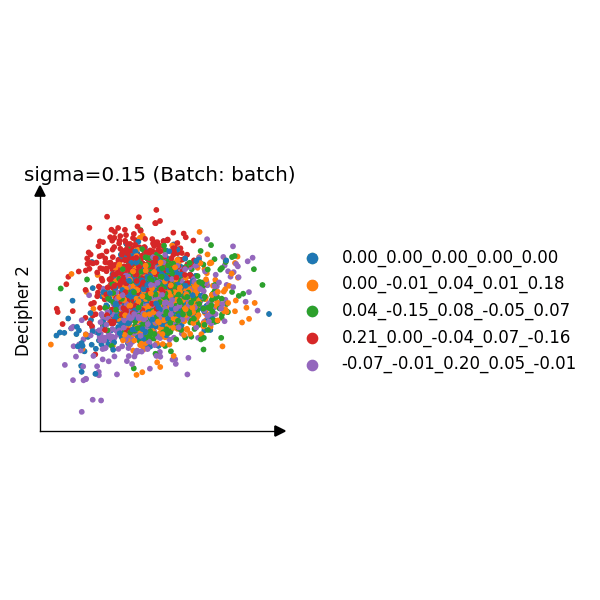

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
2026-07-24 15:09:27,152 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-07-24 15:09:27,153 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-07-24 15:09:27,175 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 0.1.
2026-07-24 15:09:27,453 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.
/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/sigma_sweep_6dz.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

,model,sigma,seed,rho,ground_truth_h5ad,trained_h5ad
0,Base Decipher,0.01,0,0.909123,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
1,Base Decipher,0.01,1,0.927384,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
2,Base Decipher,0.01,2,0.936142,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
3,Base Decipher,0.01,3,0.914899,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
4,Base Decipher,0.01,4,0.918050,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
...,...,...,...,...,...,...
115,Decipher-MF,0.15,0,0.903484,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
116,Decipher-MF,0.15,1,0.922676,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
117,Decipher-MF,0.15,2,0.934585,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
118,Decipher-MF,0.15,3,0.914905,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...


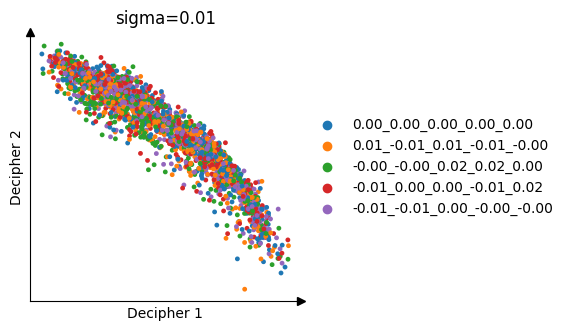

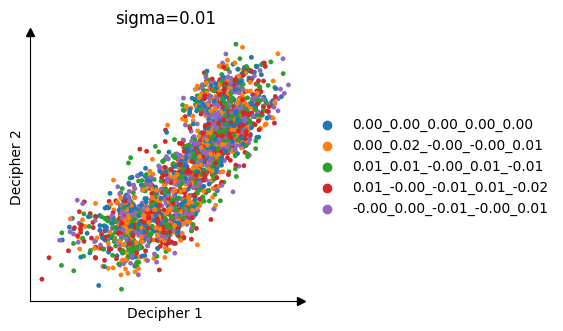

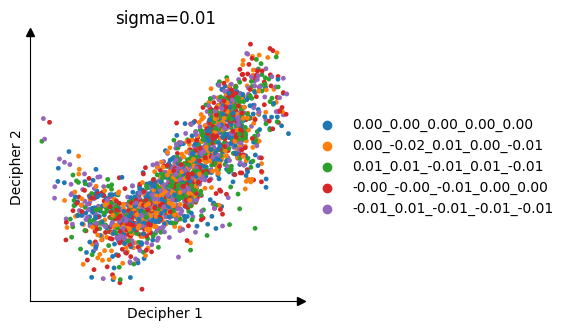

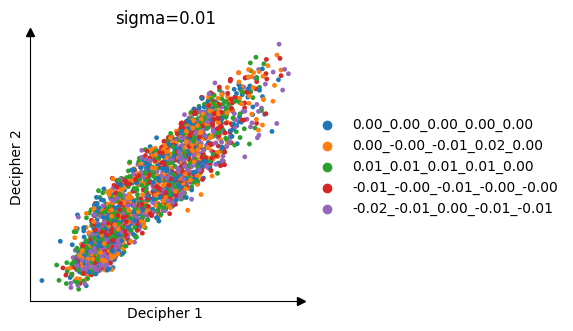

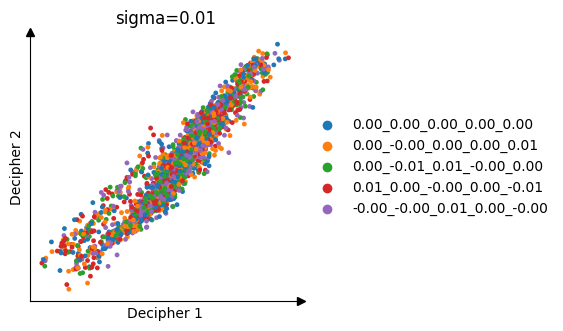

...

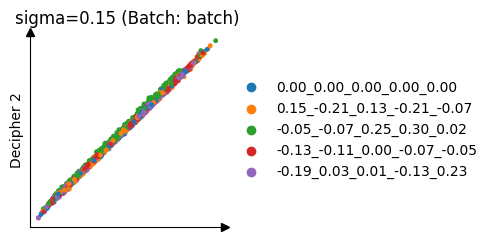

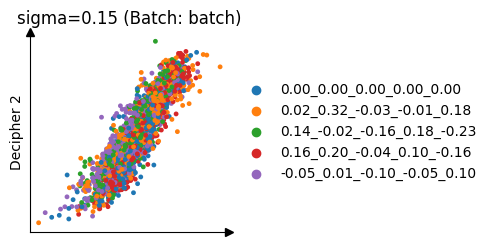

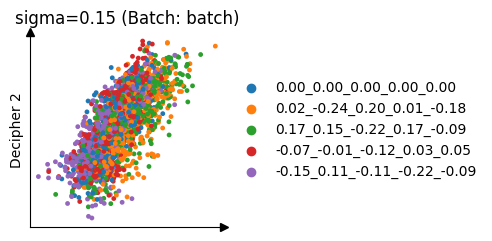

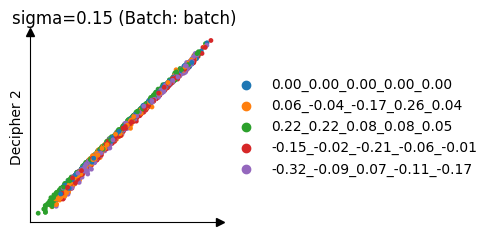

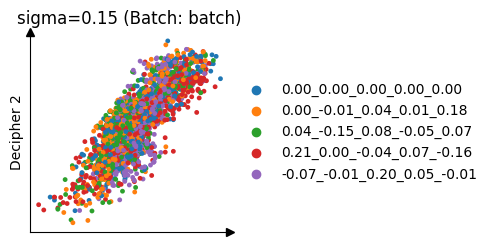

In [2]:
import os
import pandas as pd

results_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1/trained"
os.makedirs(results_dir, exist_ok=True)

models = {
    "Base Decipher": "decipher",
    "Decipher-VZ": "decipher_vz",
    "Decipher-VZ2": "decipher_vz2",
    "Decipher-MF": "decipher_mf",
}

sigmas = [0.01, 0.02, 0.03, 0.05, 0.10, 0.15]
seeds = [0, 1, 2, 3, 4]

results_csv_path = os.path.join(
    "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1", "sigma_sweep_results_6dz_bio0.1.csv"
)
records = []
for model_name, model_tag in models.items():
    for sigma in sigmas:
        for seed in seeds:
            try:
                rho, gt_path, trained_path, adata = rho_for_run(sigma=sigma, seed=seed, model=model_tag, decipher_seed=1)
                records.append({
                    "model": model_name,
                    "sigma": sigma,
                    "seed": seed,
                    "rho": rho,
                    "ground_truth_h5ad": gt_path,
                    "trained_h5ad": trained_path,
                })
            except Exception as e:
                print(f"[{model_name}] sigma={sigma} seed={seed} failed: {type(e).__name__}: {e}")
            # Write after every run so a failure partway through the sweep doesn't lose
            # already-completed results.
            pd.DataFrame(records).to_csv(results_csv_path, index=False)

results_df = pd.DataFrame(records)
results_df

## Correlation Plot

2026-07-24 15:09:31,345 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 15:09:31,359 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 15:09:31,400 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 15:09:31,421 | INFO : Substituting symbol N from STIXNonUnicode


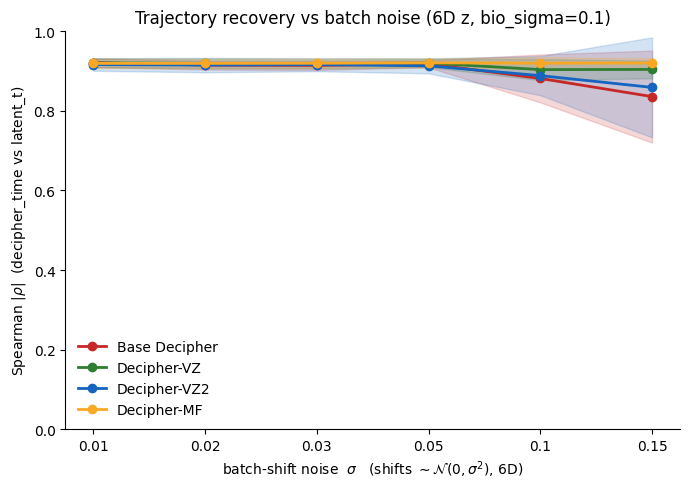

In [3]:
import numpy as np
import matplotlib.pyplot as plt

colors = {
    "Decipher-VZ": "#2E7D32",
    "Decipher-VZ2": "#1565C0",
    "Decipher-MF": "#F9A825",
    "Base Decipher": "#C62828",
}

sigmas_sorted = sorted(results_df["sigma"].unique())
x_pos = np.arange(len(sigmas_sorted))  # evenly spaced positions, one per sigma tested

fig, ax = plt.subplots(figsize=(7, 5))
for name in models:
    sub = results_df[results_df["model"] == name]
    stats = sub.groupby("sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted)
    mean = stats["mean"].to_numpy()
    sd_ = stats["std"].to_numpy()
    ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
    ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.18)

ax.set_xticks(x_pos)
ax.set_xticklabels([str(s) for s in sigmas_sorted])
ax.set_xlabel(r"batch-shift noise  $\sigma$   (shifts $\sim \mathcal{N}(0,\sigma^2)$, 6D)")
ax.set_ylabel(r"Spearman $|\rho|$  (decipher_time vs latent_t)")
ax.set_title("Trajectory recovery vs batch noise (6D z, bio_sigma=0.1)")
ax.set_ylim(0, 1); ax.axhline(0, color="0.8", lw=0.8)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("sigma_vs_correlation_6dz_bio0.1.png", dpi=200)
plt.show()

In [4]:
rho_summary = results_df.groupby("sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted).round(3)
rho_summary

,mean,std
sigma,,
0.01,0.919,0.012
0.02,0.917,0.013
0.03,0.917,0.012
0.05,0.918,0.012
0.10,0.898,0.041
0.15,0.880,0.087


## Z-space UMAP colored by batch, highest sigma
Qualitative check (per the advisor's ask): confirm the learned `decipher_z` UMAP shows batch separation at the highest sigma tested, for every model.

In [13]:
import scanpy as sc
from sklearn.metrics import silhouette_score

def load_run(results_df, sigma, model_name, seed=None):
    sub = results_df[(results_df["sigma"] == sigma) & (results_df["model"] == model_name)]
    if seed is not None:
        sub = sub[sub["seed"] == seed]
    row = sub.iloc[0]
    return row, sc.read_h5ad(row["trained_h5ad"])

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Base Decipher  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0110


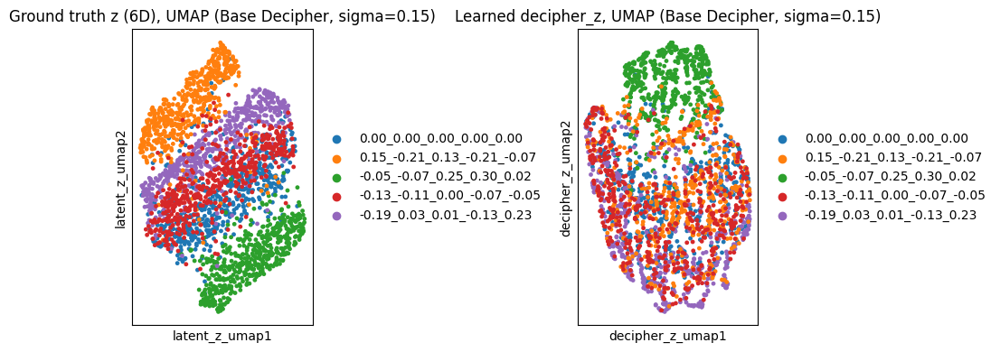

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-VZ  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0743


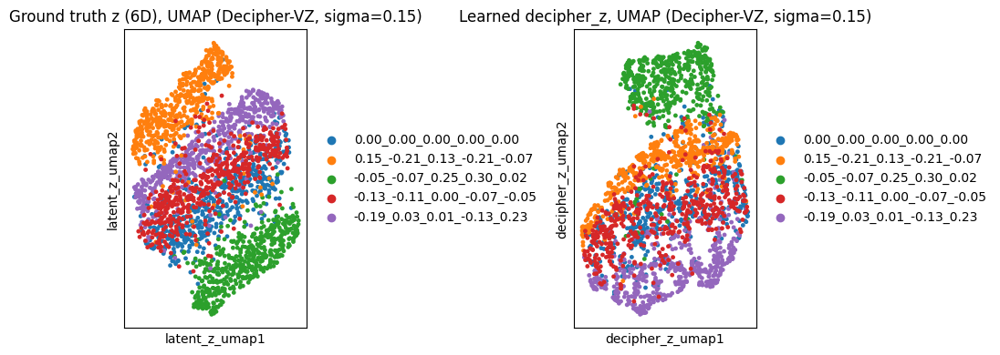

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-VZ2  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0708


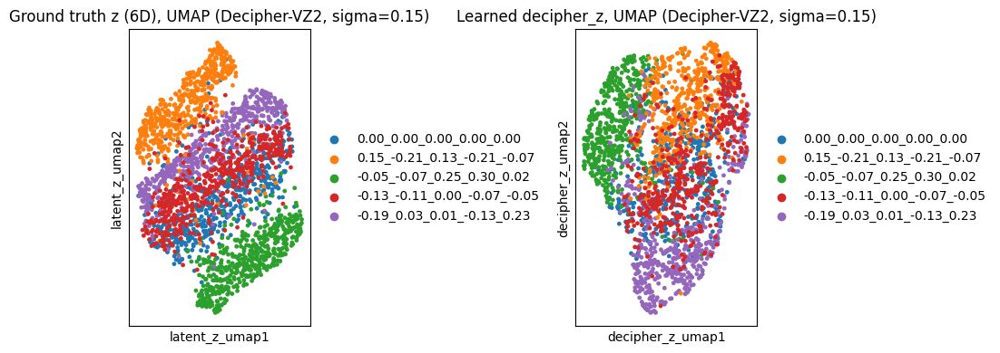

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-MF  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0072


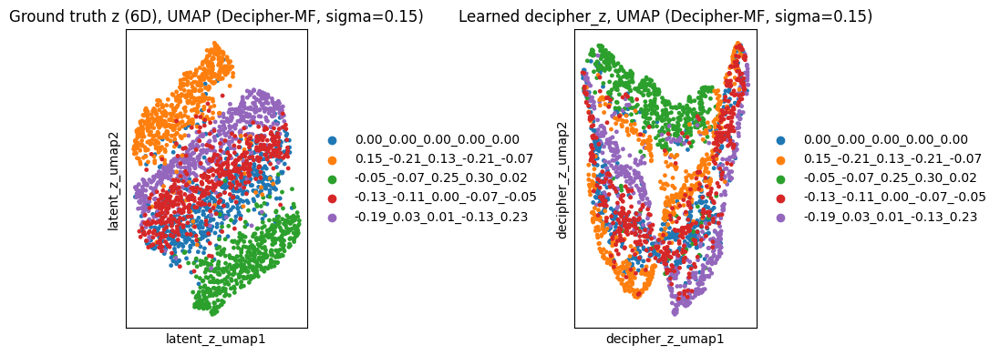

In [6]:
latent_z_cols = ["latent_z0", "latent_z1", "latent_z2", "latent_z3", "latent_z4", "latent_z5"]
sigma_max = max(sigmas_sorted)

for model_name in models:
    row, adata = load_run(results_df, sigma_max, model_name)
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma_max}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma_max}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma_max})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma_max})")
    plt.tight_layout()
    plt.show()

## Per-sigma detail: latent vs. learned pseudotime, ground truth vs. inferred z
Mirrors `8.3 sigma-sweep-4-models.ipynb`'s per-sigma layout: for each sigma, one figure per model of `latent_t` vs `decipher_time` (both on `decipher_v`), then one figure per model of ground-truth `latent_z` (6D, UMAP) vs learned `decipher_z` (UMAP), both colored by batch. All panels use seed=0.

In [7]:
model_names = list(models.keys())
latent_z_cols = ["latent_z0", "latent_z1", "latent_z2", "latent_z3", "latent_z4", "latent_z5"]
seed_for_detail = 0

### Sigma = 0.01

In [8]:
sigma = 0.01
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

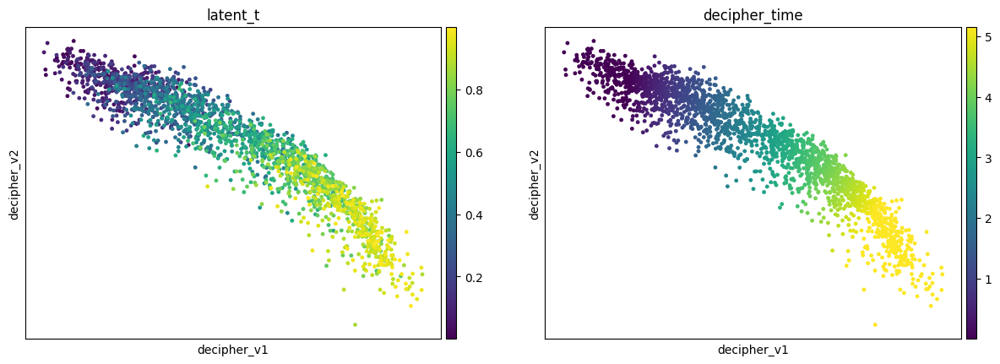

Base Decipher, sigma=0.01, seed=0, rho = 0.9091


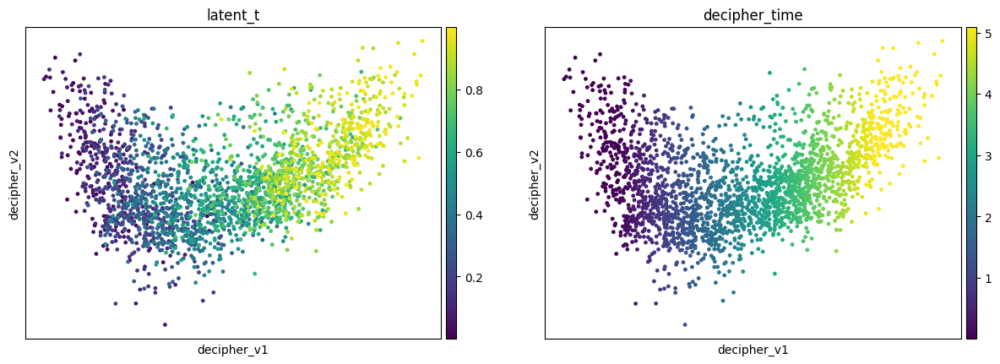

Decipher-VZ, sigma=0.01, seed=0, rho = 0.9080


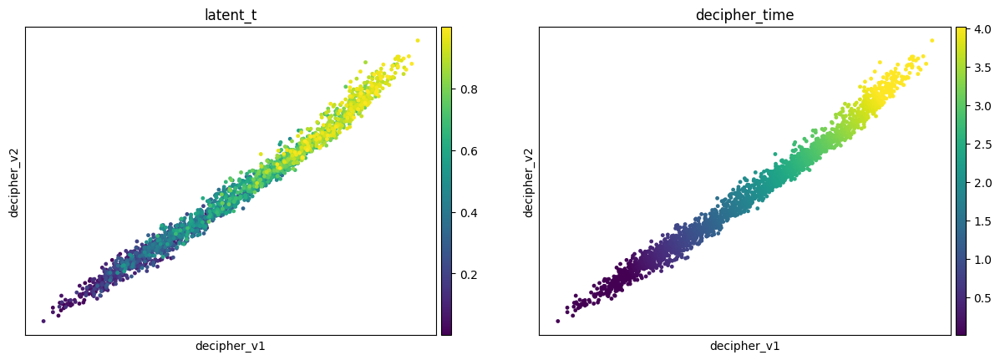

Decipher-VZ2, sigma=0.01, seed=0, rho = 0.9114


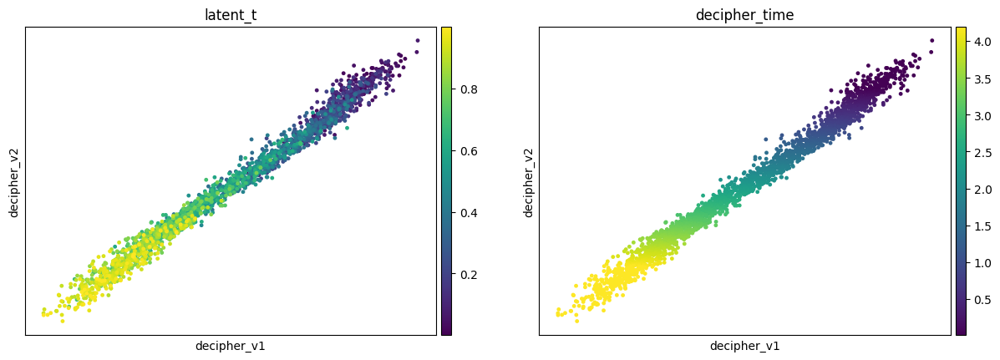

Decipher-MF, sigma=0.01, seed=0, rho = 0.9074


In [9]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.01  ground truth z silhouette (by batch) = -0.0226
Base Decipher  sigma=0.01  learned decipher_z silhouette (by batch) = -0.0427


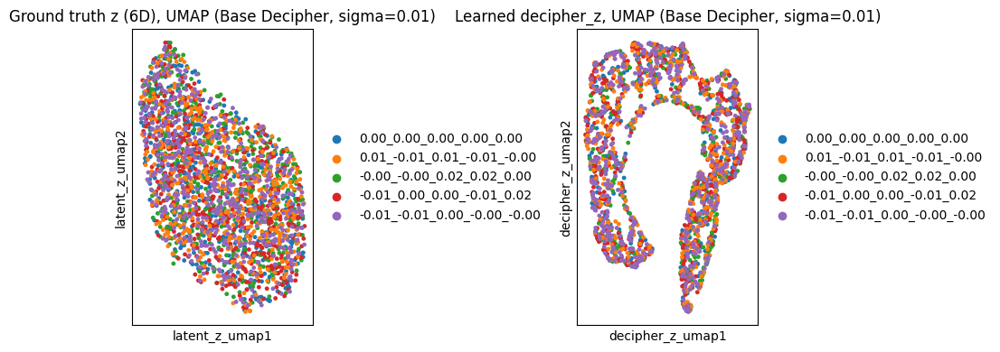

Decipher-VZ  sigma=0.01  ground truth z silhouette (by batch) = -0.0226
Decipher-VZ  sigma=0.01  learned decipher_z silhouette (by batch) = -0.0439


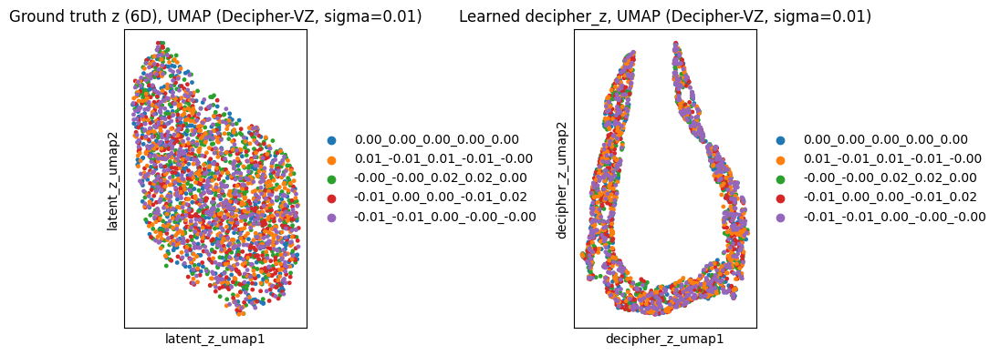

Decipher-VZ2  sigma=0.01  ground truth z silhouette (by batch) = -0.0226
Decipher-VZ2  sigma=0.01  learned decipher_z silhouette (by batch) = -0.0434


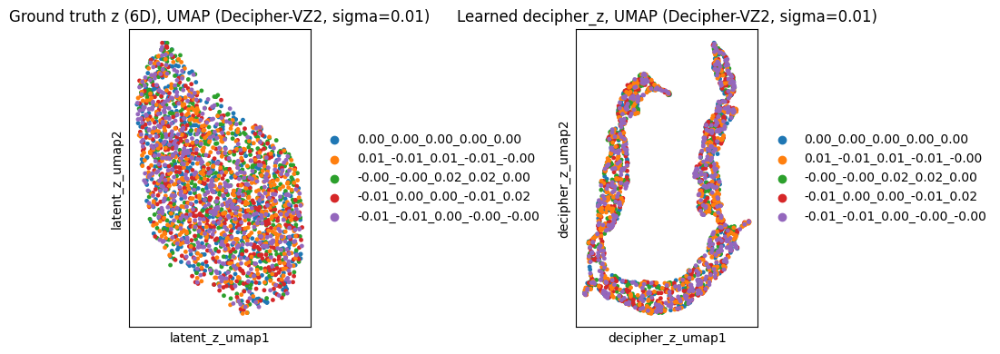

Decipher-MF  sigma=0.01  ground truth z silhouette (by batch) = -0.0226
Decipher-MF  sigma=0.01  learned decipher_z silhouette (by batch) = -0.0413


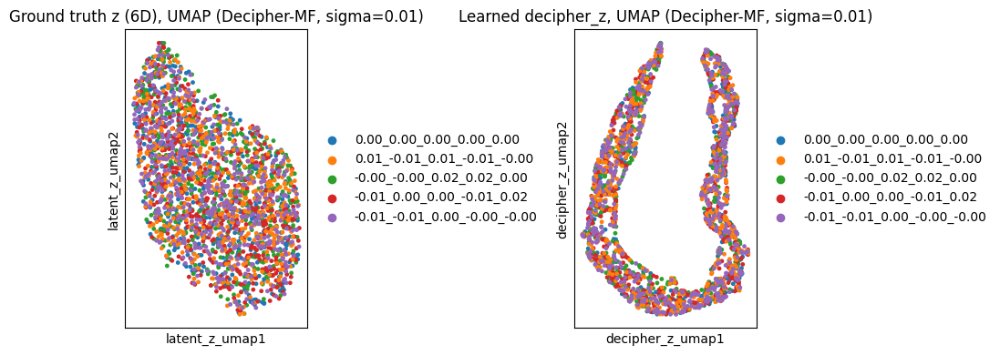

In [10]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.02

In [11]:
sigma = 0.02
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

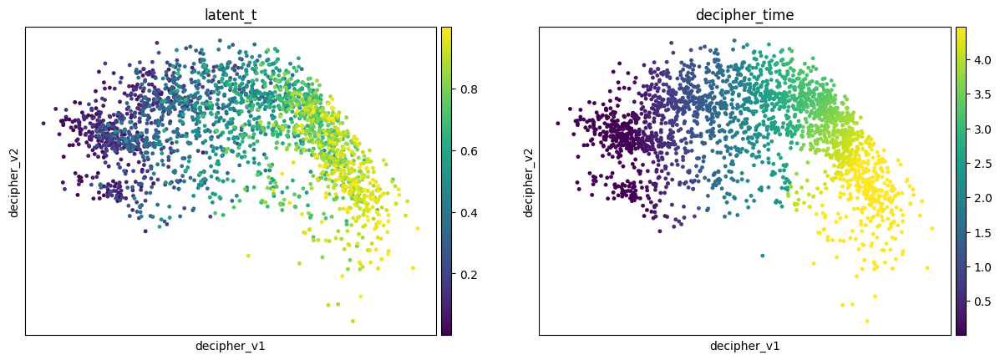

Base Decipher, sigma=0.02, seed=0, rho = 0.9077


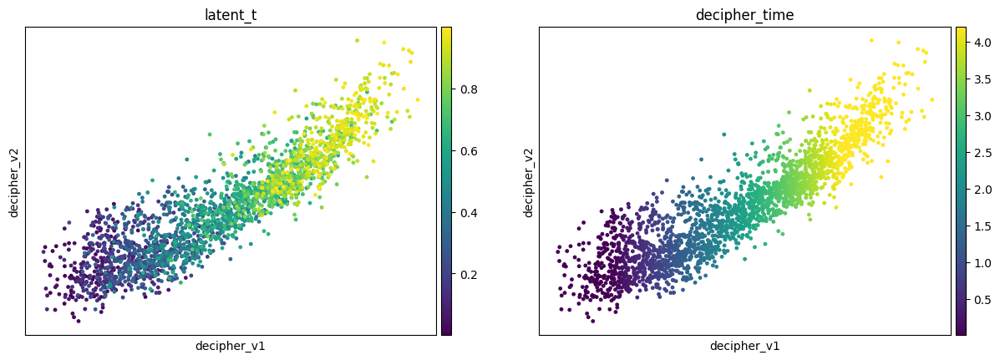

Decipher-VZ, sigma=0.02, seed=0, rho = 0.9088


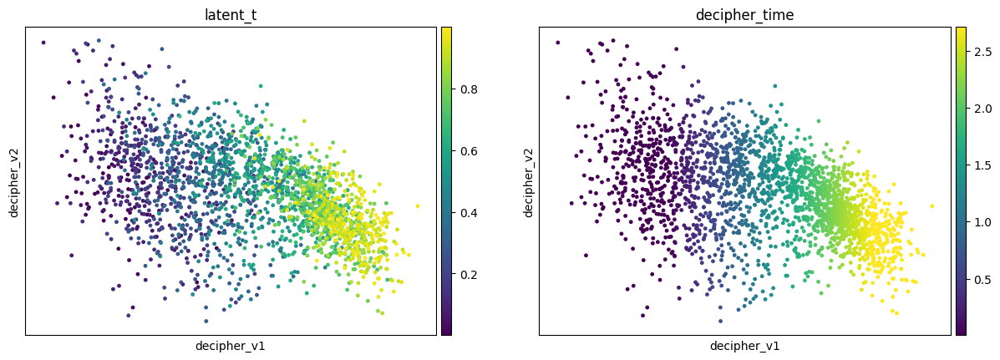

Decipher-VZ2, sigma=0.02, seed=0, rho = 0.8905


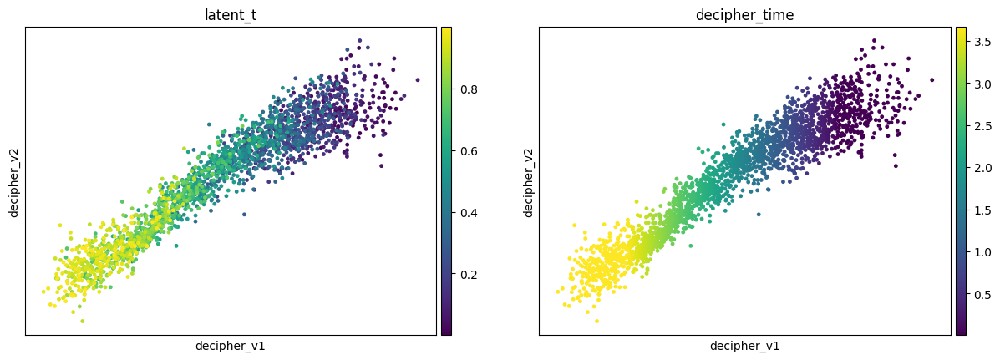

Decipher-MF, sigma=0.02, seed=0, rho = 0.9069


In [12]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.02  ground truth z silhouette (by batch) = -0.0224
Base Decipher  sigma=0.02  learned decipher_z silhouette (by batch) = -0.0419


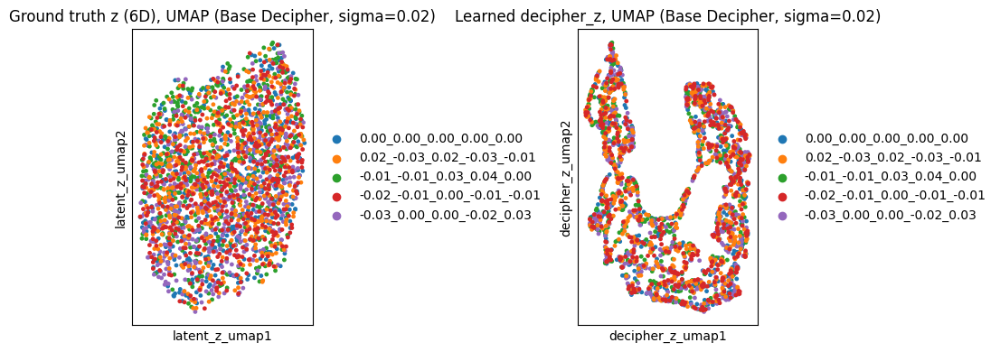

Decipher-VZ  sigma=0.02  ground truth z silhouette (by batch) = -0.0224
Decipher-VZ  sigma=0.02  learned decipher_z silhouette (by batch) = -0.0414


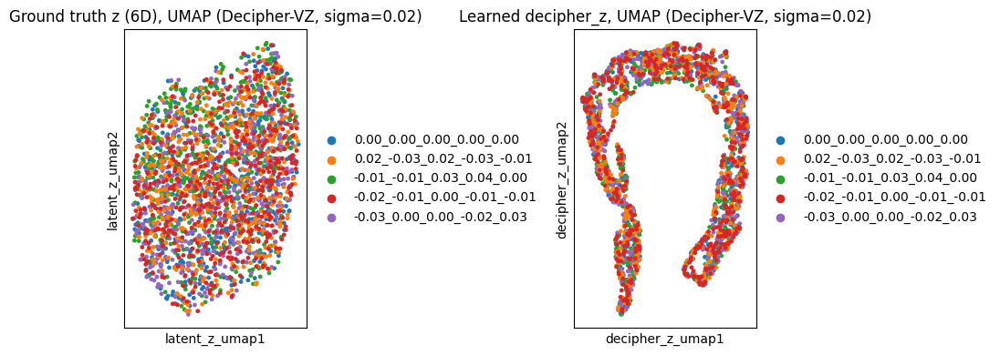

Decipher-VZ2  sigma=0.02  ground truth z silhouette (by batch) = -0.0224
Decipher-VZ2  sigma=0.02  learned decipher_z silhouette (by batch) = -0.0460


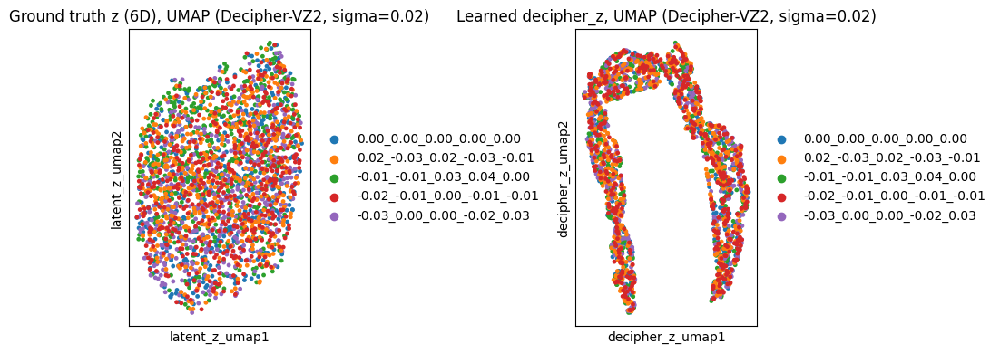

Decipher-MF  sigma=0.02  ground truth z silhouette (by batch) = -0.0224
Decipher-MF  sigma=0.02  learned decipher_z silhouette (by batch) = -0.0402


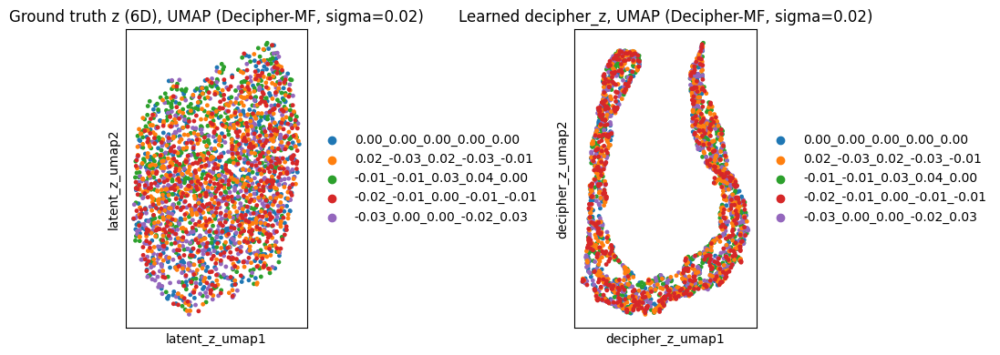

In [13]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.03

In [14]:
sigma = 0.03
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

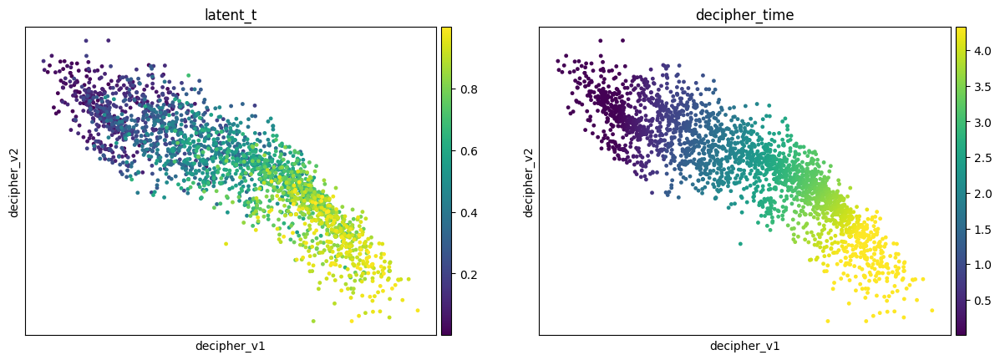

Base Decipher, sigma=0.03, seed=0, rho = 0.9096


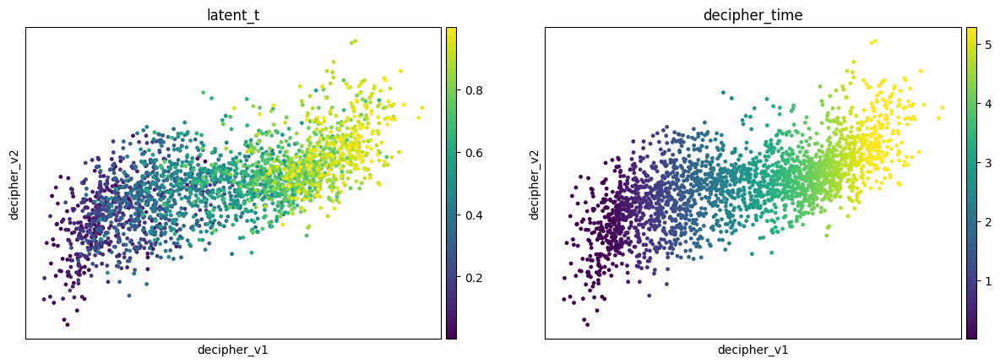

Decipher-VZ, sigma=0.03, seed=0, rho = 0.9075


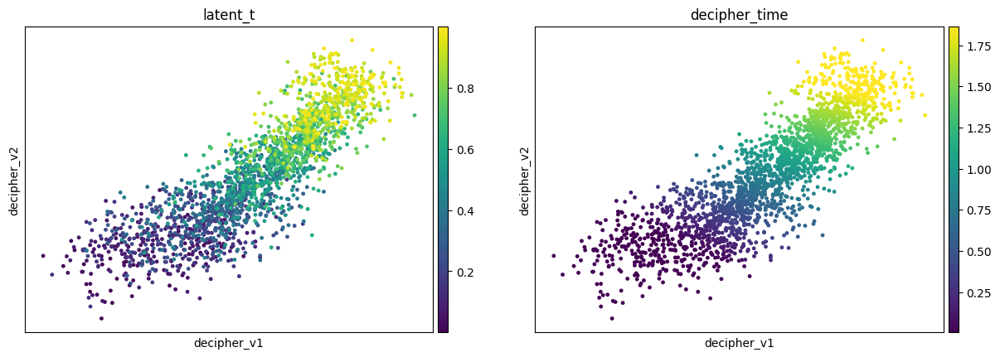

Decipher-VZ2, sigma=0.03, seed=0, rho = 0.8955


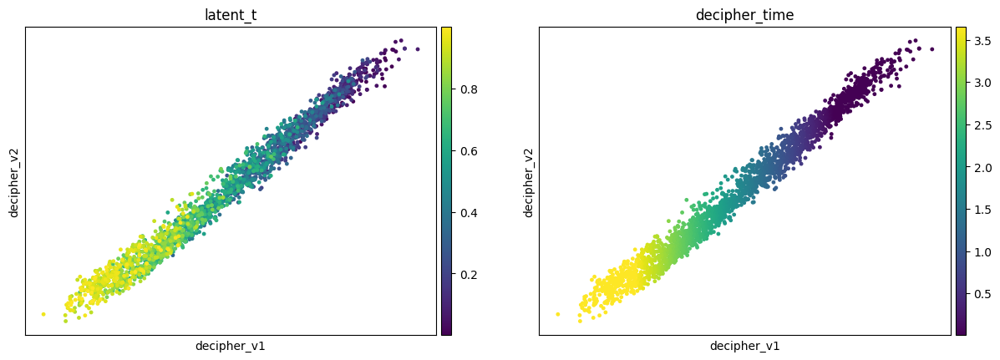

Decipher-MF, sigma=0.03, seed=0, rho = 0.9042


In [15]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.03  ground truth z silhouette (by batch) = -0.0198
Base Decipher  sigma=0.03  learned decipher_z silhouette (by batch) = -0.0496


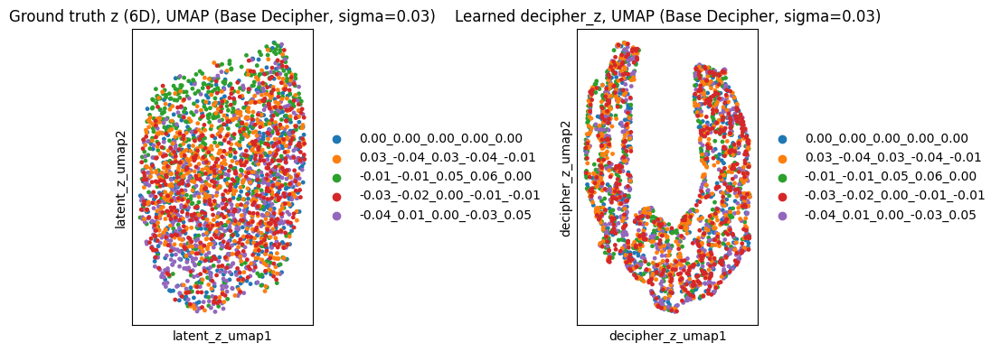

Decipher-VZ  sigma=0.03  ground truth z silhouette (by batch) = -0.0198
Decipher-VZ  sigma=0.03  learned decipher_z silhouette (by batch) = -0.0520


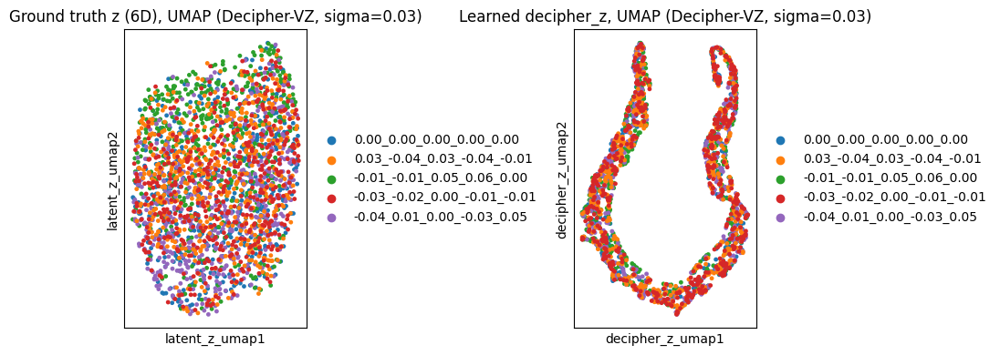

Decipher-VZ2  sigma=0.03  ground truth z silhouette (by batch) = -0.0198
Decipher-VZ2  sigma=0.03  learned decipher_z silhouette (by batch) = -0.0419


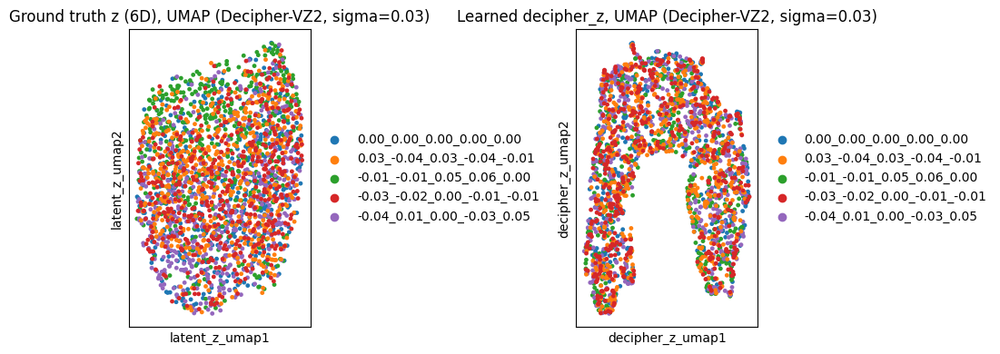

Decipher-MF  sigma=0.03  ground truth z silhouette (by batch) = -0.0198
Decipher-MF  sigma=0.03  learned decipher_z silhouette (by batch) = -0.0467


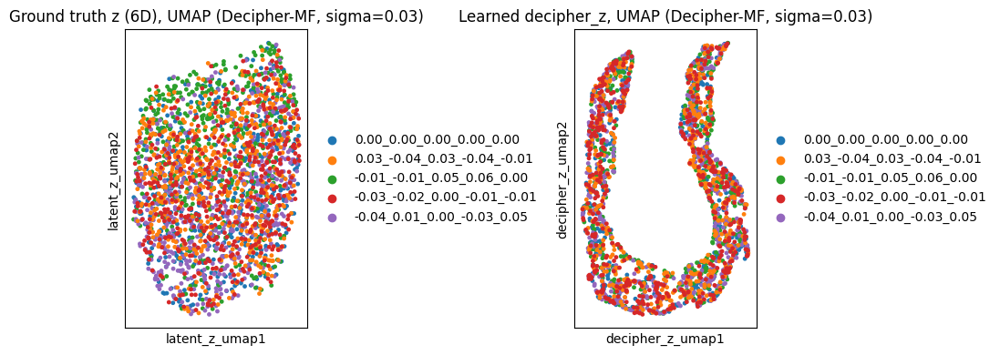

In [16]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.05

In [17]:
sigma = 0.05
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

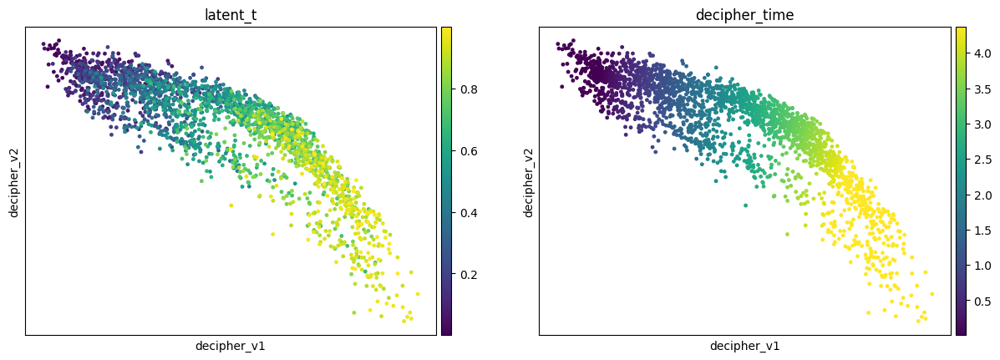

Base Decipher, sigma=0.05, seed=0, rho = 0.9069


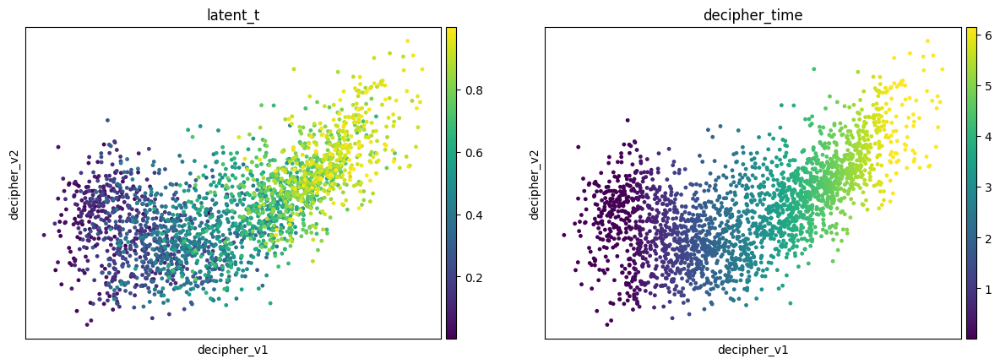

Decipher-VZ, sigma=0.05, seed=0, rho = 0.9053


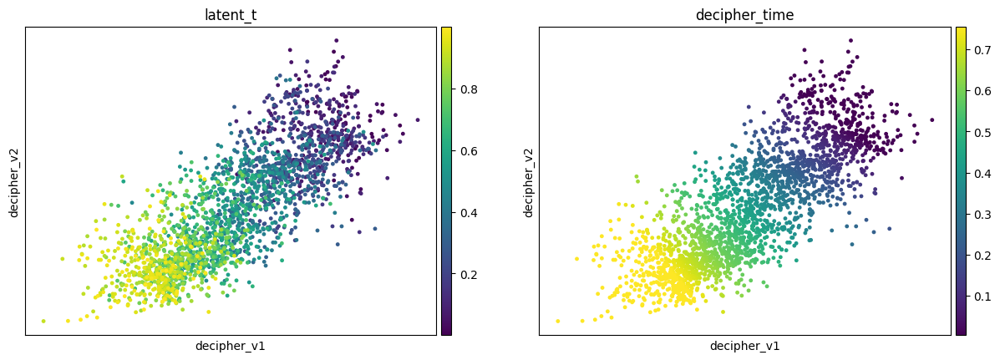

Decipher-VZ2, sigma=0.05, seed=0, rho = 0.8933


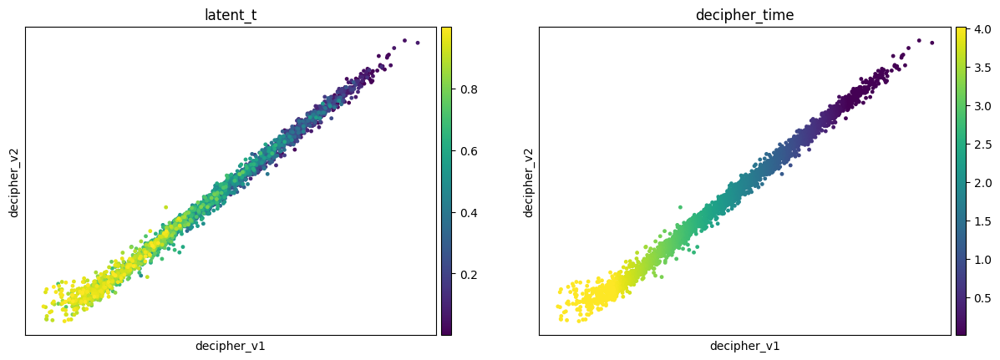

Decipher-MF, sigma=0.05, seed=0, rho = 0.9043


In [18]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.05  ground truth z silhouette (by batch) = -0.0085
Base Decipher  sigma=0.05  learned decipher_z silhouette (by batch) = -0.0526


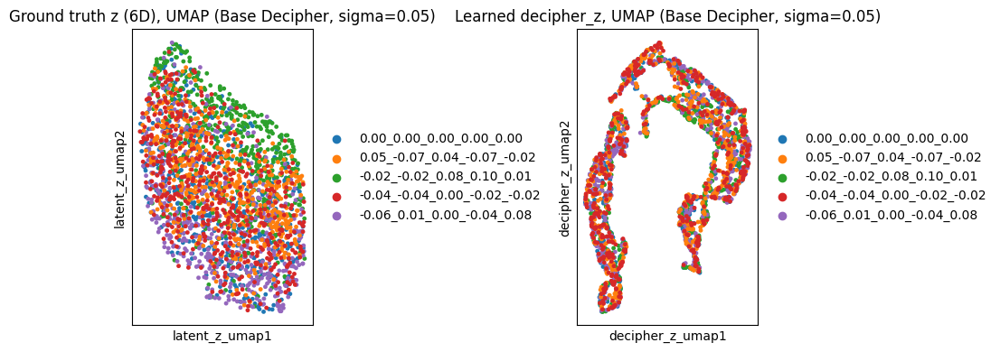

Decipher-VZ  sigma=0.05  ground truth z silhouette (by batch) = -0.0085
Decipher-VZ  sigma=0.05  learned decipher_z silhouette (by batch) = -0.0586


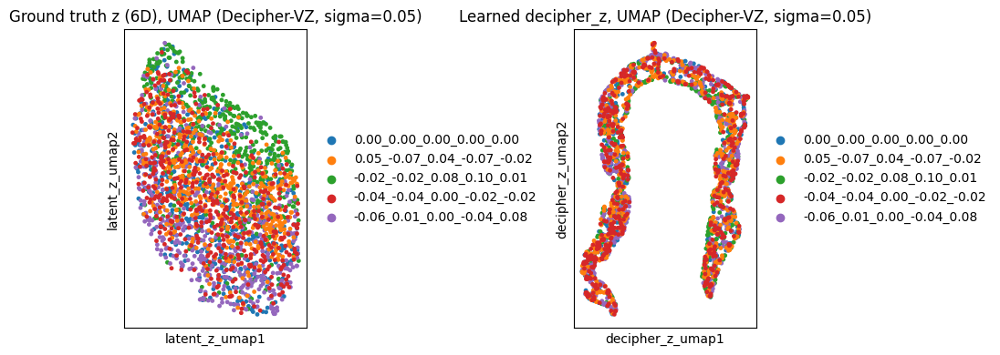

Decipher-VZ2  sigma=0.05  ground truth z silhouette (by batch) = -0.0085
Decipher-VZ2  sigma=0.05  learned decipher_z silhouette (by batch) = -0.0547


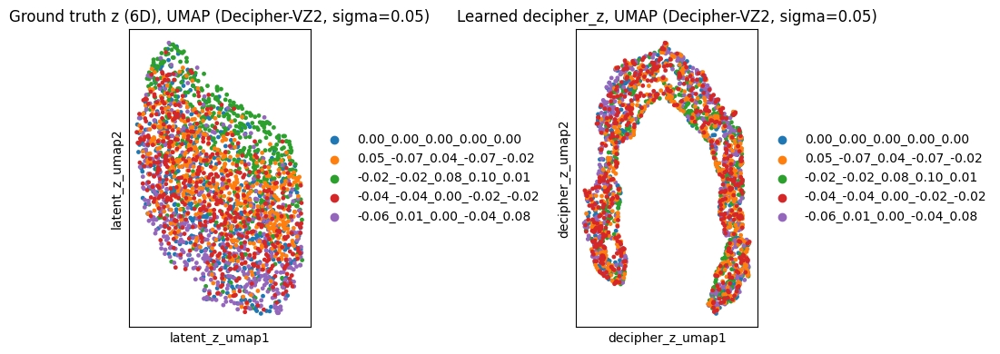

Decipher-MF  sigma=0.05  ground truth z silhouette (by batch) = -0.0085
Decipher-MF  sigma=0.05  learned decipher_z silhouette (by batch) = -0.0436


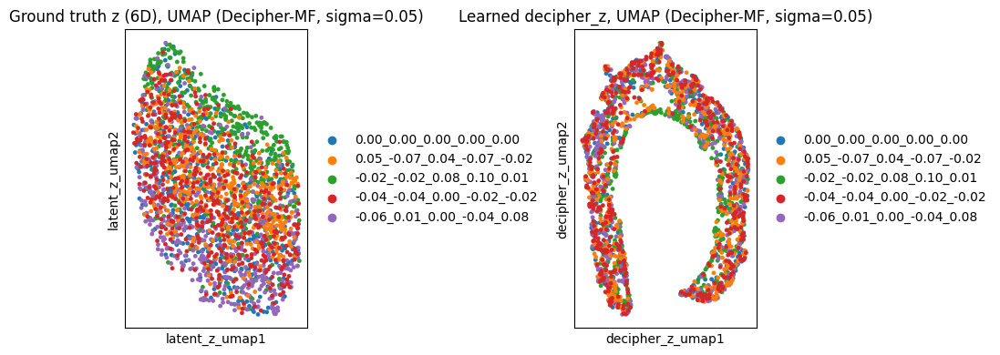

In [19]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.1

In [20]:
sigma = 0.1
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

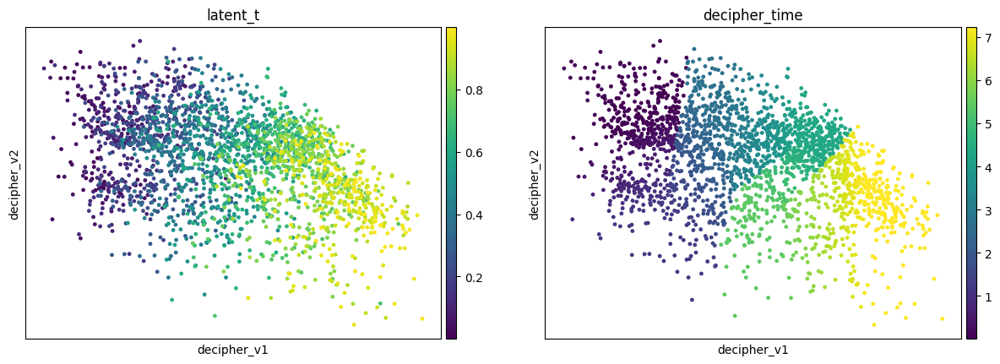

Base Decipher, sigma=0.1, seed=0, rho = 0.8689


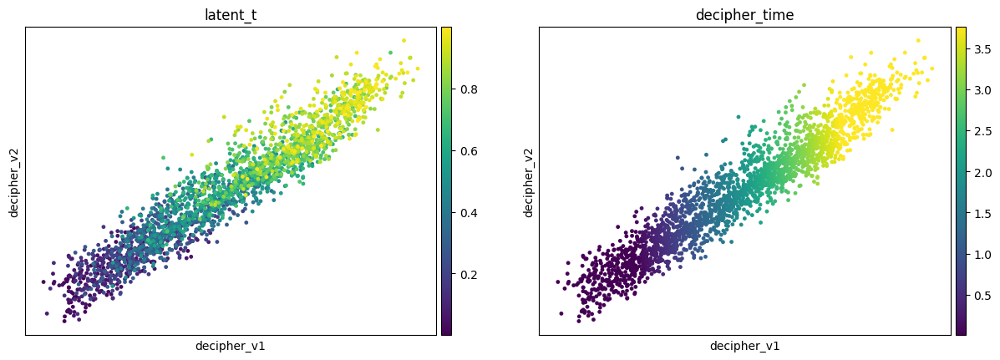

Decipher-VZ, sigma=0.1, seed=0, rho = 0.8719


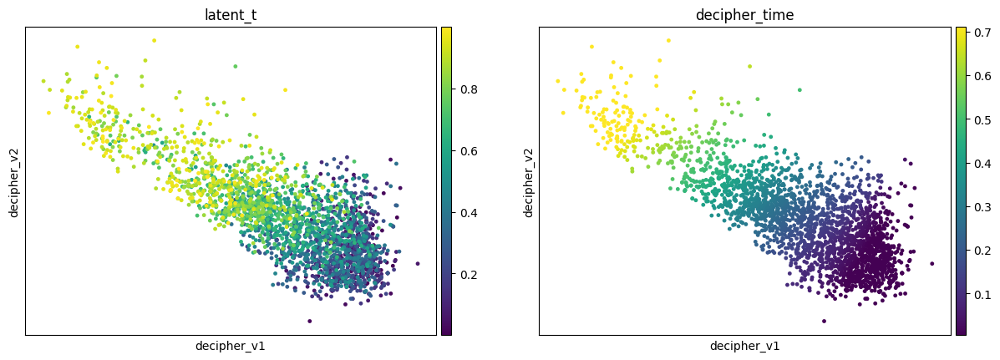

Decipher-VZ2, sigma=0.1, seed=0, rho = 0.8236


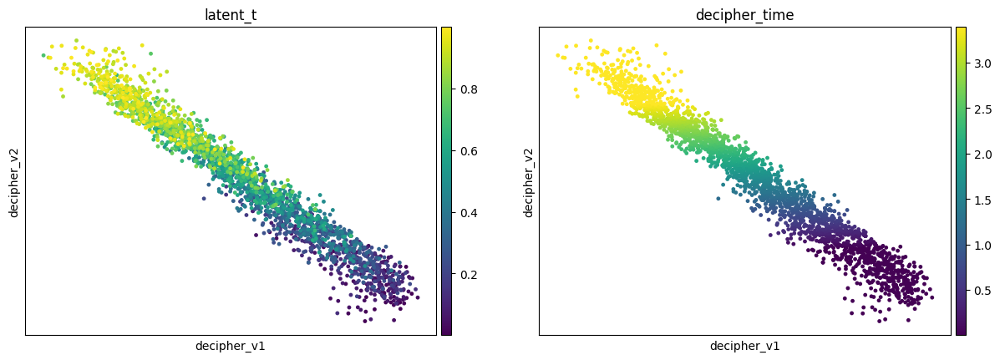

Decipher-MF, sigma=0.1, seed=0, rho = 0.8954


In [21]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.1  ground truth z silhouette (by batch) = 0.0495
Base Decipher  sigma=0.1  learned decipher_z silhouette (by batch) = -0.0427


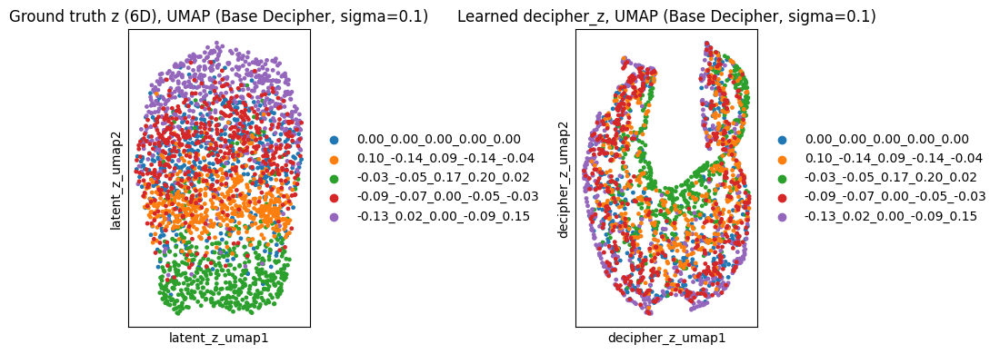

Decipher-VZ  sigma=0.1  ground truth z silhouette (by batch) = 0.0495
Decipher-VZ  sigma=0.1  learned decipher_z silhouette (by batch) = -0.0715


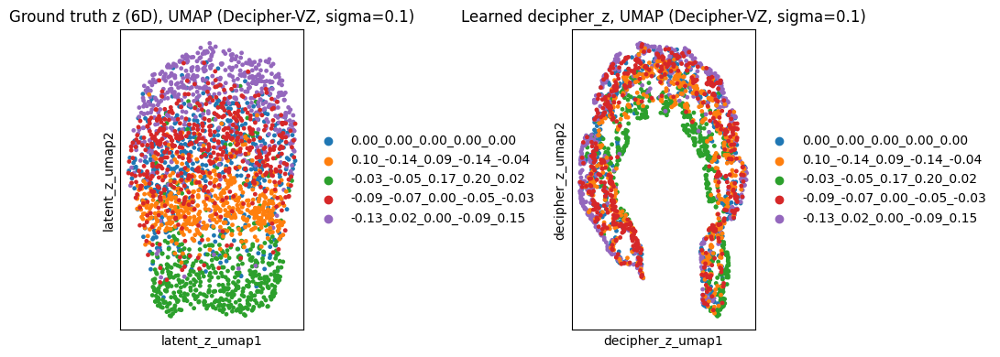

Decipher-VZ2  sigma=0.1  ground truth z silhouette (by batch) = 0.0495
Decipher-VZ2  sigma=0.1  learned decipher_z silhouette (by batch) = -0.0520


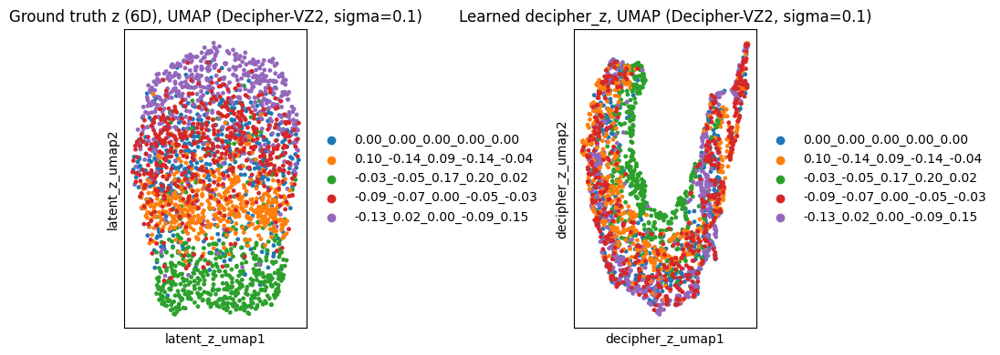

Decipher-MF  sigma=0.1  ground truth z silhouette (by batch) = 0.0495
Decipher-MF  sigma=0.1  learned decipher_z silhouette (by batch) = -0.0335


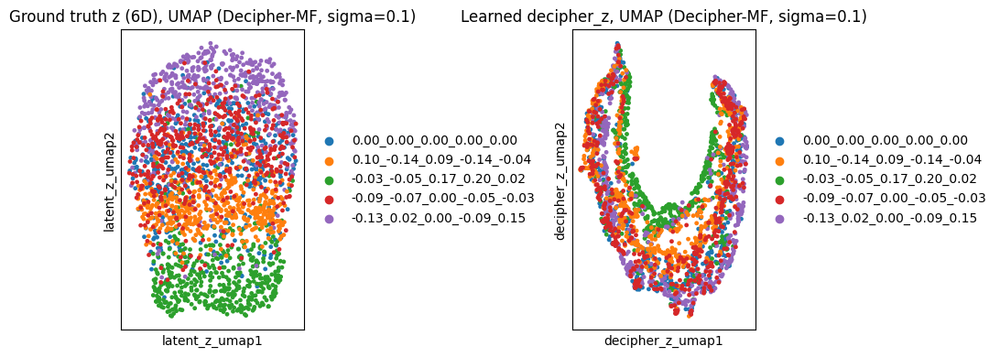

In [22]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.15

In [23]:
sigma = 0.15
runs = {name: load_run(results_df, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

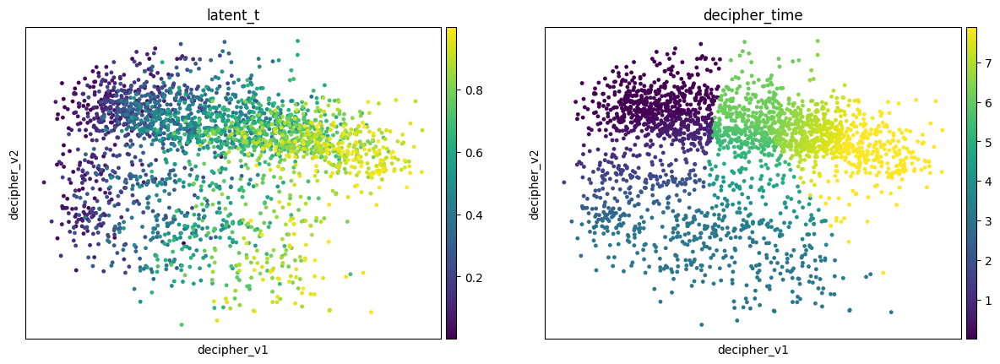

Base Decipher, sigma=0.15, seed=0, rho = 0.7892


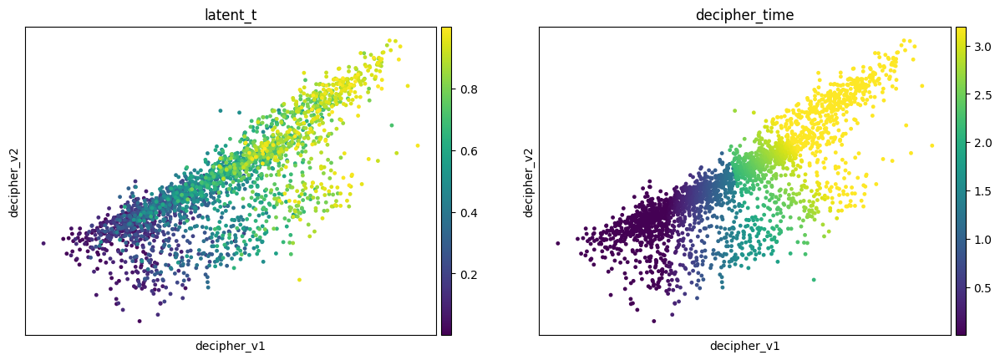

Decipher-VZ, sigma=0.15, seed=0, rho = 0.8942


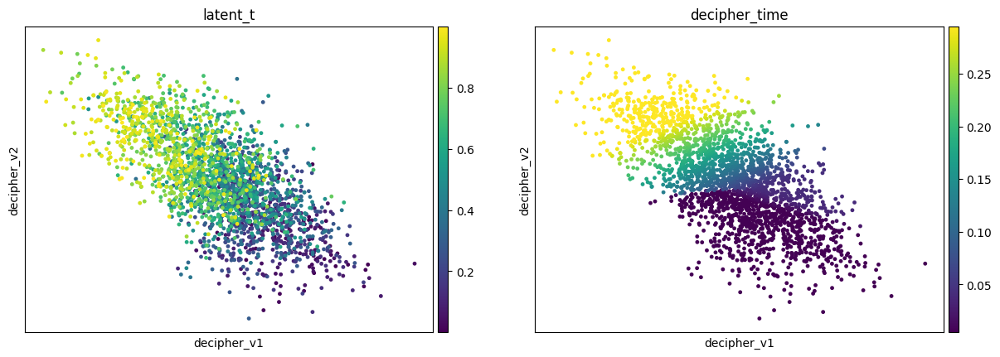

Decipher-VZ2, sigma=0.15, seed=0, rho = 0.6391


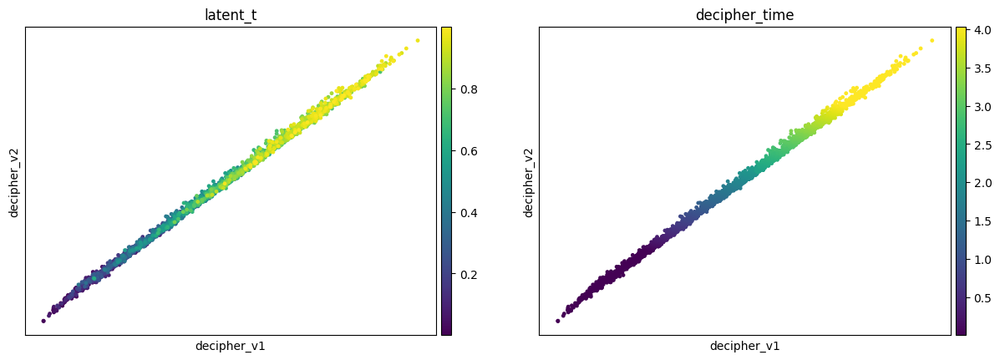

Decipher-MF, sigma=0.15, seed=0, rho = 0.9035


In [24]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Base Decipher  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0110


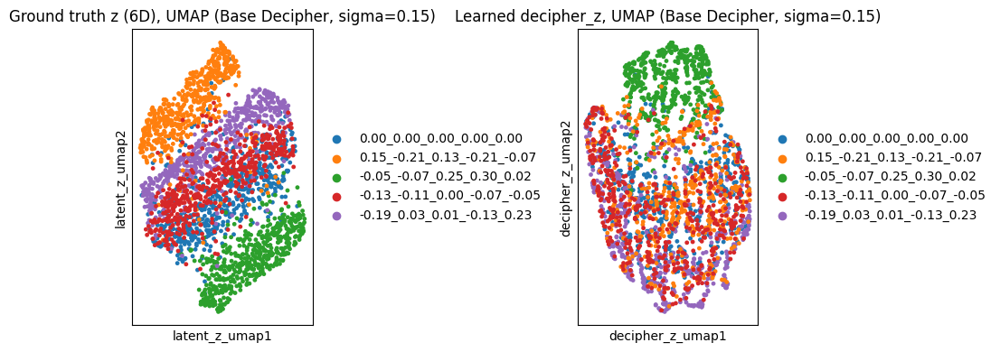

Decipher-VZ  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-VZ  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0743


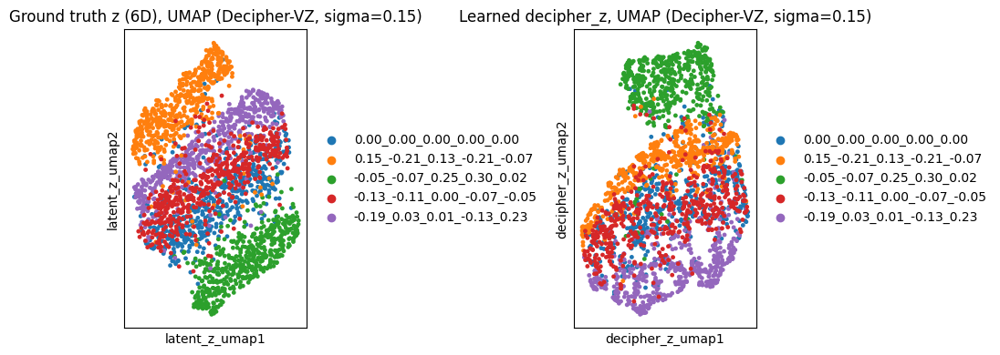

Decipher-VZ2  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-VZ2  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0708


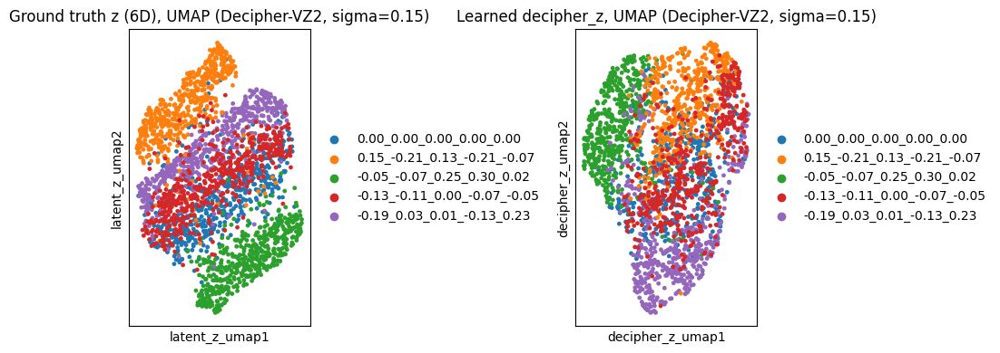

Decipher-MF  sigma=0.15  ground truth z silhouette (by batch) = 0.1246
Decipher-MF  sigma=0.15  learned decipher_z silhouette (by batch) = 0.0072


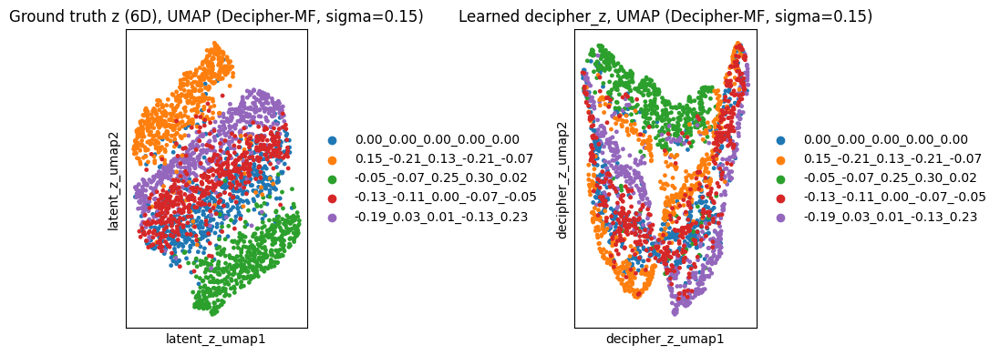

In [25]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

## High Sigmas

Epoch 263 (batch 22/22) | | train elbo: 62.25 (last epoch: 62.25) | val ll: 62.51:  26%|██▋       | 263/1000 [01:00<02:48,  4.38it/s]2026-07-24 15:57:50,640 | INFO : Early stopping has been triggered.
2026-07-24 15:57:50,643 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-07-24 15:57:50,643 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-07-24 15:57:50,643 | INFO : Saving decipher model with run_id 2026-07-24-15-57-50-acyclic-seething-open.


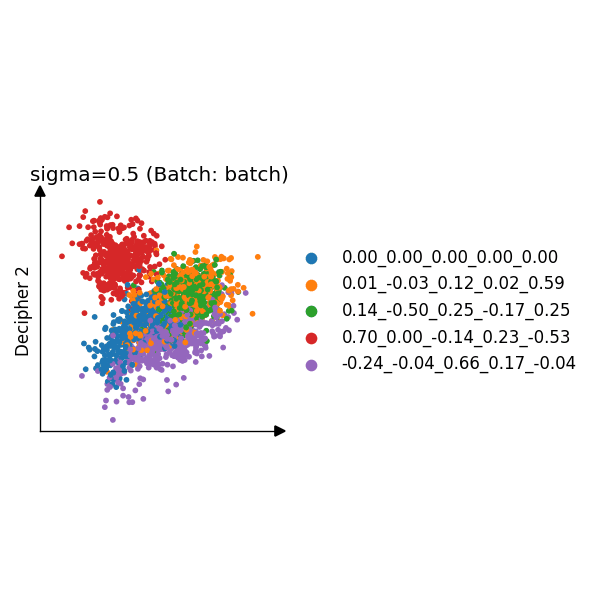

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
2026-07-24 15:57:51,513 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-07-24 15:57:51,514 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-07-24 15:57:51,536 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 0.1.
2026-07-24 15:57:51,846 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.
/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/sigma_sweep_6dz.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

,model,sigma,seed,rho,ground_truth_h5ad,trained_h5ad
0,Base Decipher,0.2,0,0.609898,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
1,Base Decipher,0.2,1,0.765204,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
2,Base Decipher,0.2,2,0.819739,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
3,Base Decipher,0.2,3,0.758070,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
4,Base Decipher,0.2,4,0.912336,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
...,...,...,...,...,...,...
75,Decipher-MF,0.5,0,0.001206,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
76,Decipher-MF,0.5,1,0.914968,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
77,Decipher-MF,0.5,2,0.922347,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...
78,Decipher-MF,0.5,3,0.895990,/Users/alanxie/CodingProjects/Columbia/Azizi L...,/Users/alanxie/CodingProjects/Columbia/Azizi L...


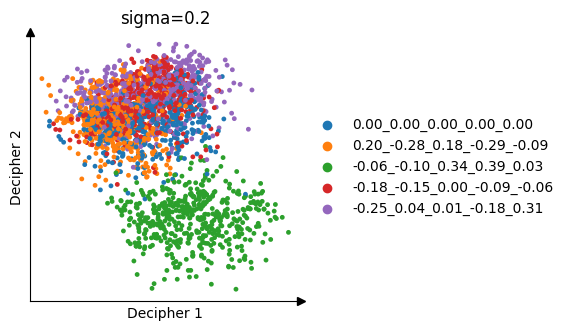

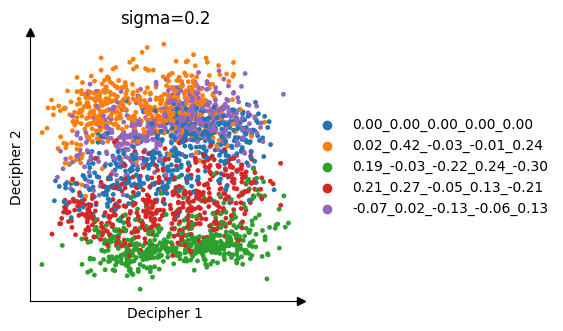

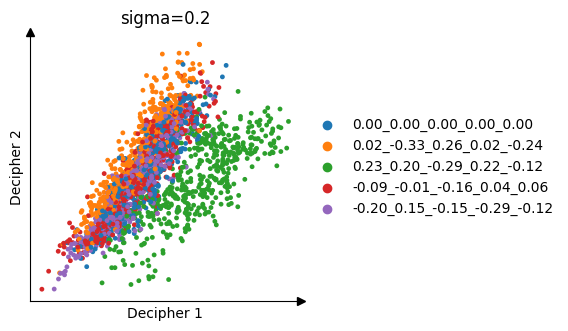

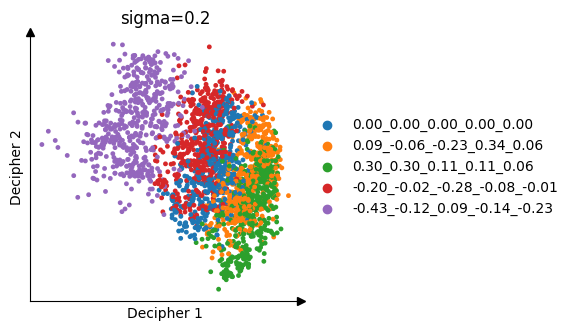

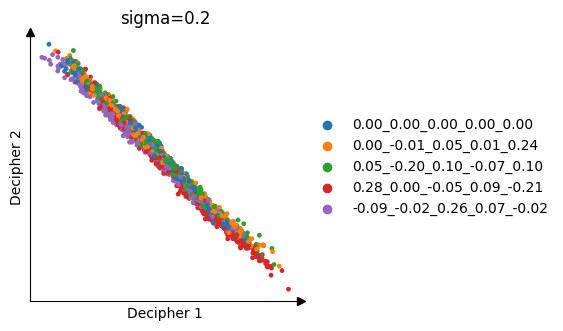

...

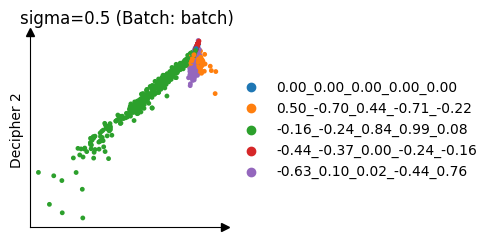

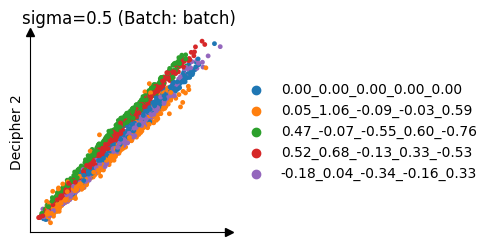

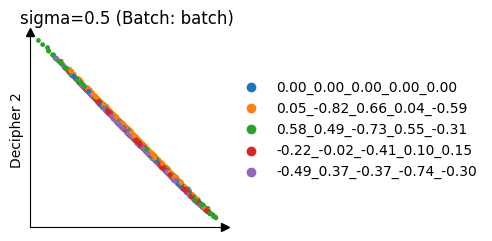

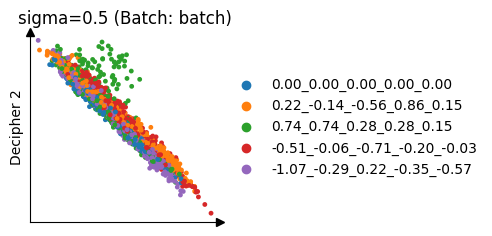

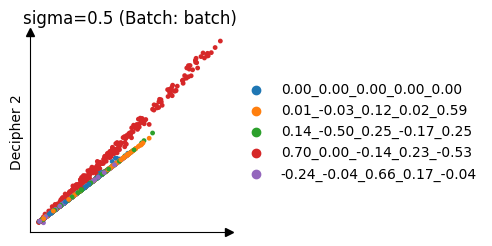

In [4]:
import os
import pandas as pd

results_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1/trained"
os.makedirs(results_dir, exist_ok=True)

models = {
    "Base Decipher": "decipher",
    "Decipher-VZ": "decipher_vz",
    "Decipher-VZ2": "decipher_vz2",
    "Decipher-MF": "decipher_mf",
}

sigmas_high = [0.2, 0.3, 0.4, 0.5]
seeds = [0, 1, 2, 3, 4]

results_csv_path_high = os.path.join(
    "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1", "sigma_sweep_results_6dz_bio0.1_highsigma.csv"
)
records_high = []
for model_name, model_tag in models.items():
    for sigma in sigmas_high:
        for seed in seeds:
            try:
                rho, gt_path, trained_path, adata = rho_for_run(sigma=sigma, seed=seed, model=model_tag, decipher_seed=1)
                records_high.append({
                    "model": model_name,
                    "sigma": sigma,
                    "seed": seed,
                    "rho": rho,
                    "ground_truth_h5ad": gt_path,
                    "trained_h5ad": trained_path,
                })
            except Exception as e:
                print(f"[{model_name}] sigma={sigma} seed={seed} failed: {type(e).__name__}: {e}")
            # Write after every run so a failure partway through the sweep doesn't lose
            # already-completed results.
            pd.DataFrame(records_high).to_csv(results_csv_path_high, index=False)

results_df_high = pd.DataFrame(records_high)
results_df_high

## Combined correlation plot (all sigmas: 0.01-0.5)
Combines the original sweep (`results_df`, sigma 0.01-0.15) with the extended high-sigma sweep (`results_df_high`, sigma 0.2-0.5) into one comparison plot across the full range tested.

In [6]:
results_csv_path = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1/sigma_sweep_results_6dz_bio0.1.csv"
results_df = pd.read_csv(results_csv_path)

results_csv_path_high = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Adata/6dz_bio_sigma_0.1/sigma_sweep_results_6dz_bio0.1_highsigma.csv"
results_df_high = pd.read_csv(results_csv_path_high)

models = {
    "Base Decipher": "decipher",
    "Decipher-VZ": "decipher_vz",
    "Decipher-VZ2": "decipher_vz2",
    "Decipher-MF": "decipher_mf",
}
colors = {
    "Decipher-VZ": "#2E7D32",
    "Decipher-VZ2": "#1565C0",
    "Decipher-MF": "#F9A825",
    "Base Decipher": "#C62828",
}


2026-07-24 16:11:47,826 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 16:11:47,846 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 16:11:47,899 | INFO : Substituting symbol N from STIXNonUnicode
2026-07-24 16:11:47,922 | INFO : Substituting symbol N from STIXNonUnicode


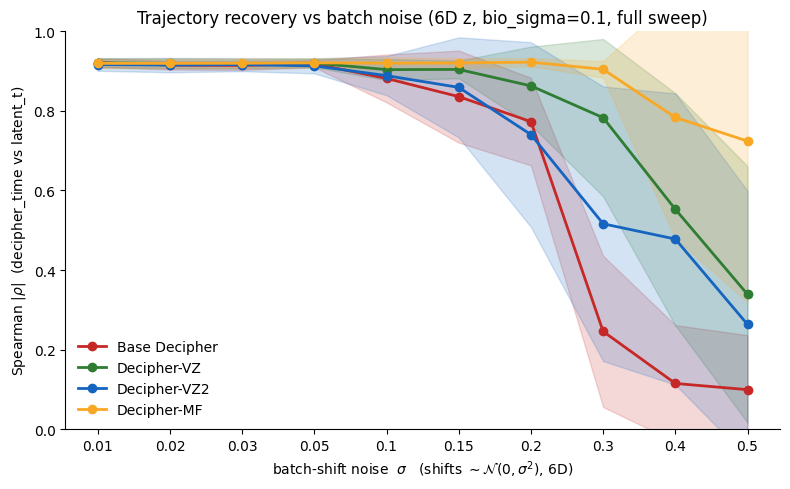

In [9]:
import numpy as np
import matplotlib.pyplot as plt

results_df_all = pd.concat([results_df, results_df_high], ignore_index=True)
sigmas_all_sorted = sorted(results_df_all["sigma"].unique())
x_pos_all = np.arange(len(sigmas_all_sorted))

fig, ax = plt.subplots(figsize=(8, 5))
for name in models:
    sub = results_df_all[results_df_all["model"] == name]
    stats = sub.groupby("sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_all_sorted)
    mean = stats["mean"].to_numpy()
    sd_ = stats["std"].to_numpy()
    ax.plot(x_pos_all, mean, marker="o", color=colors[name], label=name, linewidth=2)
    ax.fill_between(x_pos_all, mean - sd_, mean + sd_, color=colors[name], alpha=0.18)

ax.set_xticks(x_pos_all)
ax.set_xticklabels([str(s) for s in sigmas_all_sorted])
ax.set_xlabel(r"batch-shift noise  $\sigma$   (shifts $\sim \mathcal{N}(0,\sigma^2)$, 6D)")
ax.set_ylabel(r"Spearman $|\rho|$  (decipher_time vs latent_t)")
ax.set_title("Trajectory recovery vs batch noise (6D z, bio_sigma=0.1, full sweep)")
ax.set_ylim(0, 1); ax.axhline(0, color="0.8", lw=0.8)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("sigma_vs_correlation_6dz_bio0.1_full.png", dpi=200)
plt.show()

## Per-sigma detail: extended sweep (sigma = 0.2-0.5)
Same per-sigma layout as above, applied to the extended high-sigma runs (`results_df_high`). All panels use seed=0.

### Sigma = 0.2

In [11]:
model_names = list(models.keys())
latent_z_cols = ["latent_z0", "latent_z1", "latent_z2", "latent_z3", "latent_z4", "latent_z5"]
seed_for_detail = 0

In [14]:
sigma = 0.2
runs = {name: load_run(results_df_high, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

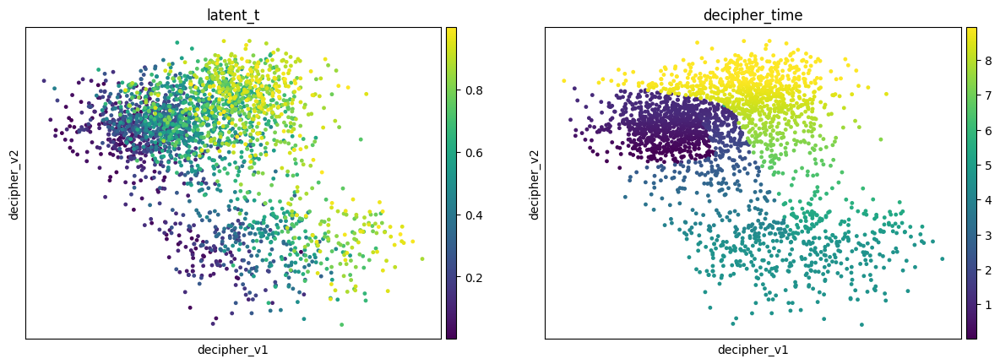

Base Decipher, sigma=0.2, seed=0, rho = 0.6099


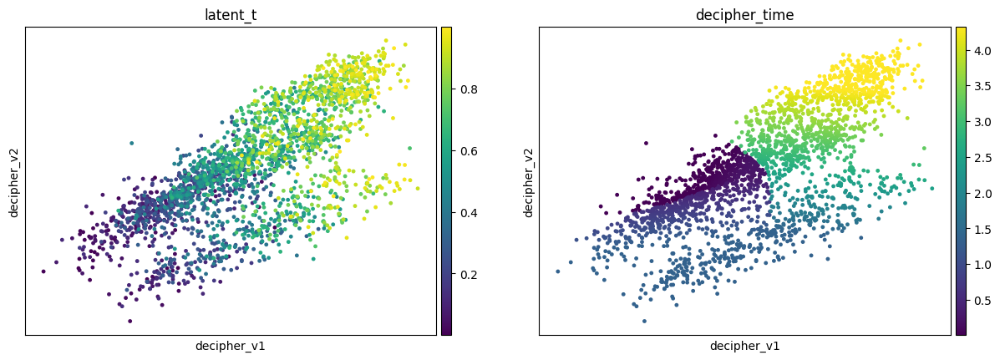

Decipher-VZ, sigma=0.2, seed=0, rho = 0.6913


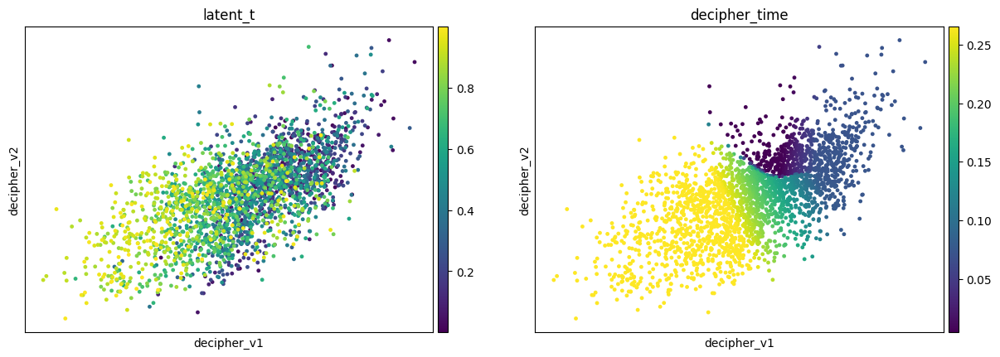

Decipher-VZ2, sigma=0.2, seed=0, rho = 0.4936


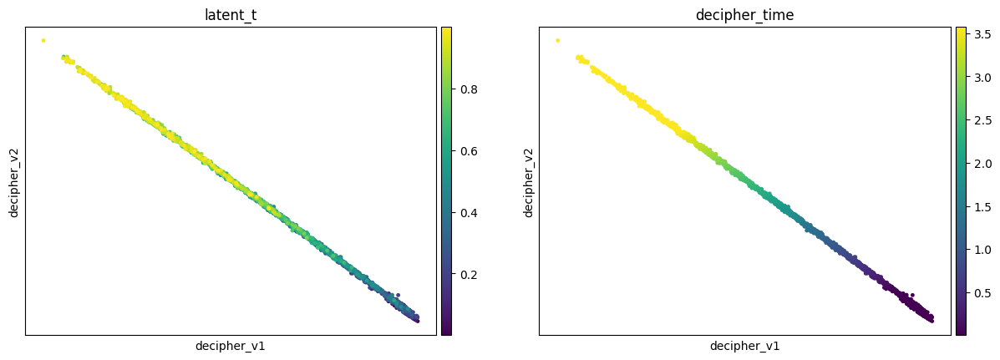

Decipher-MF, sigma=0.2, seed=0, rho = 0.9071


In [15]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.2  ground truth z silhouette (by batch) = 0.2043
Base Decipher  sigma=0.2  learned decipher_z silhouette (by batch) = 0.1035


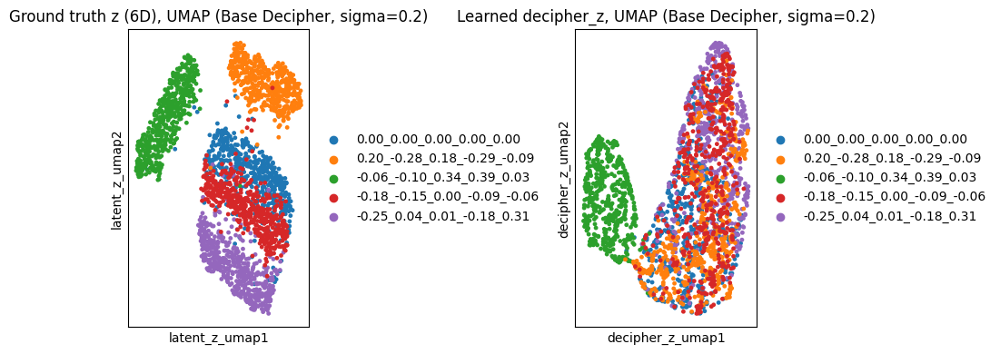

Decipher-VZ  sigma=0.2  ground truth z silhouette (by batch) = 0.2043
Decipher-VZ  sigma=0.2  learned decipher_z silhouette (by batch) = 0.1997


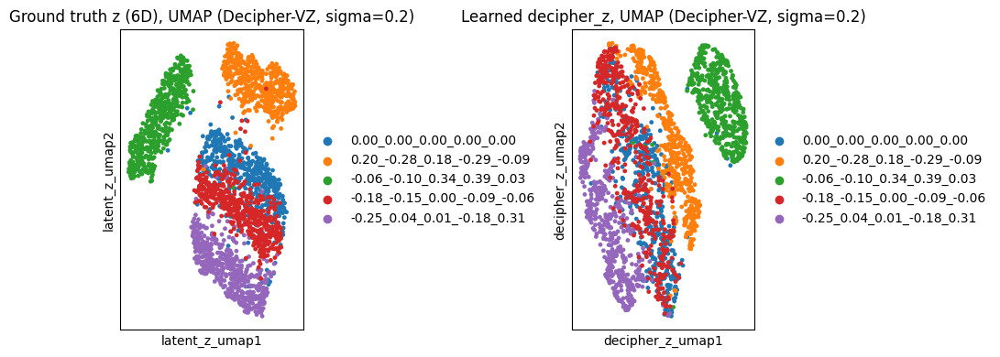

Decipher-VZ2  sigma=0.2  ground truth z silhouette (by batch) = 0.2043
Decipher-VZ2  sigma=0.2  learned decipher_z silhouette (by batch) = 0.1456


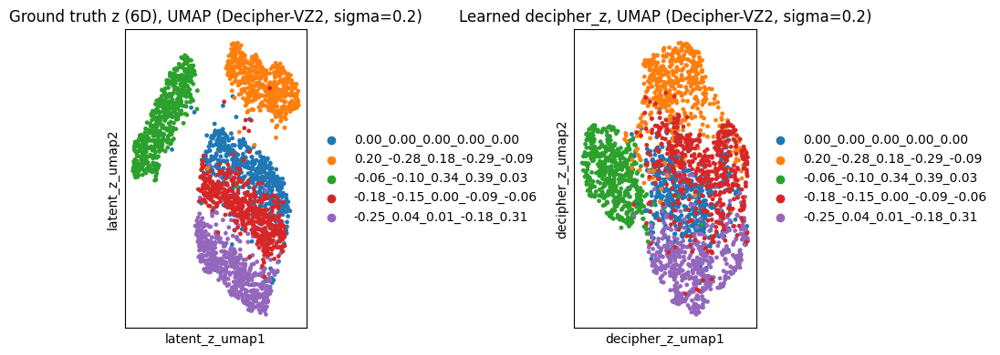

Decipher-MF  sigma=0.2  ground truth z silhouette (by batch) = 0.2043
Decipher-MF  sigma=0.2  learned decipher_z silhouette (by batch) = 0.0462


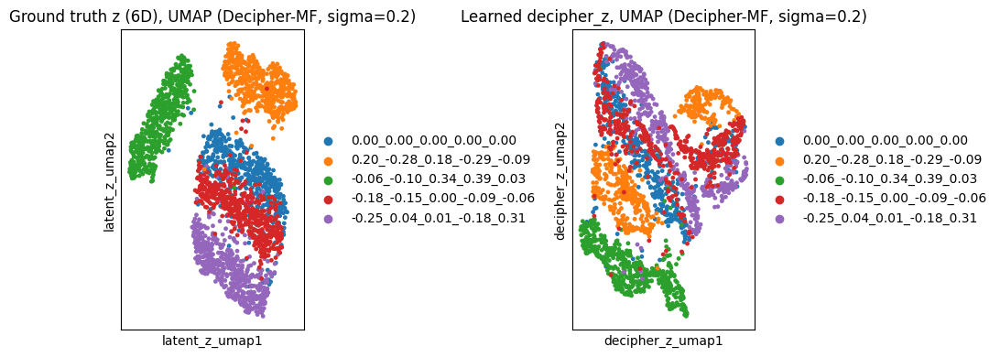

In [16]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.3

In [17]:
sigma = 0.3
runs = {name: load_run(results_df_high, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

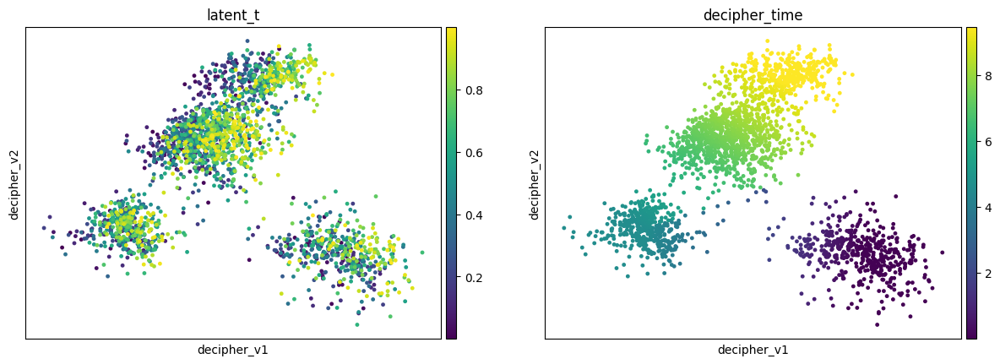

Base Decipher, sigma=0.3, seed=0, rho = 0.1130


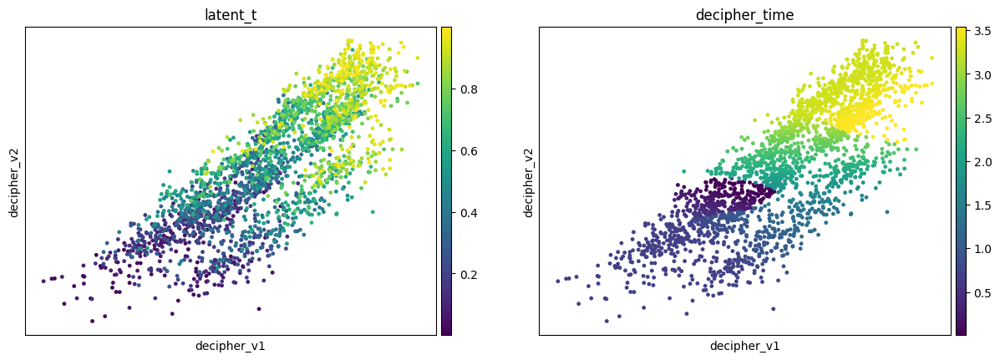

Decipher-VZ, sigma=0.3, seed=0, rho = 0.7219


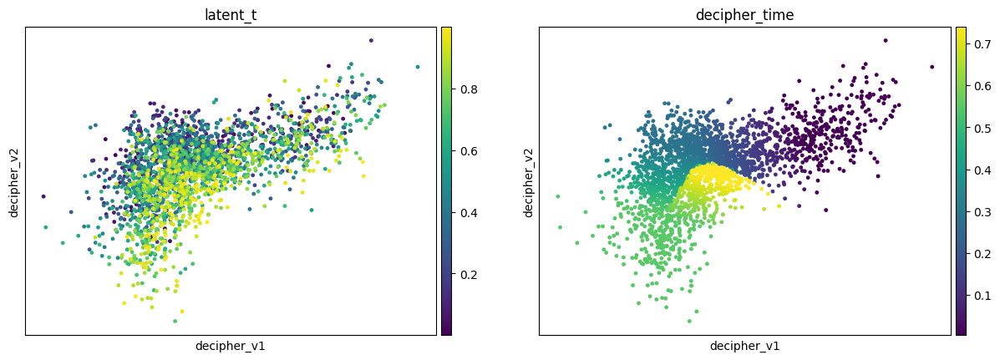

Decipher-VZ2, sigma=0.3, seed=0, rho = 0.2631


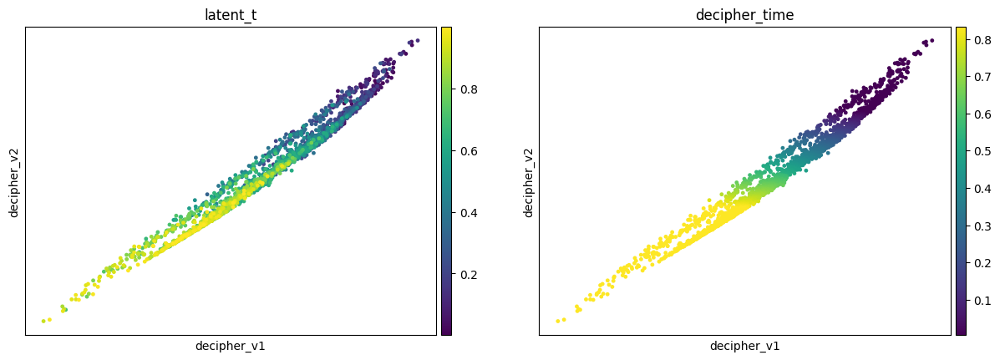

Decipher-MF, sigma=0.3, seed=0, rho = 0.8831


In [18]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.3  ground truth z silhouette (by batch) = 0.3394
Base Decipher  sigma=0.3  learned decipher_z silhouette (by batch) = 0.4267


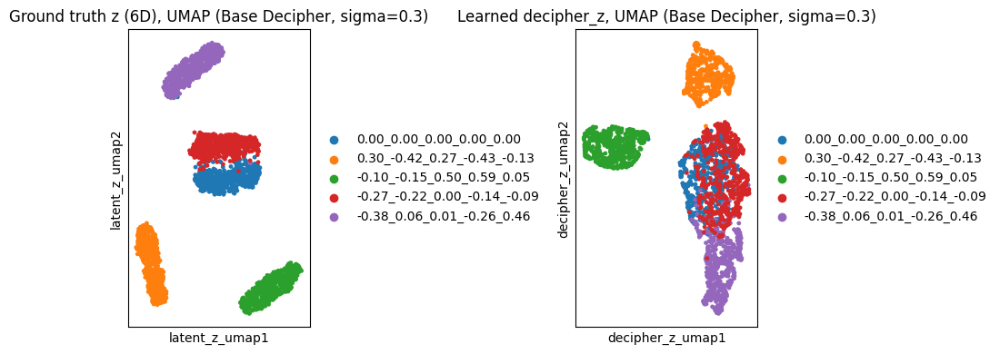

Decipher-VZ  sigma=0.3  ground truth z silhouette (by batch) = 0.3394
Decipher-VZ  sigma=0.3  learned decipher_z silhouette (by batch) = 0.3511


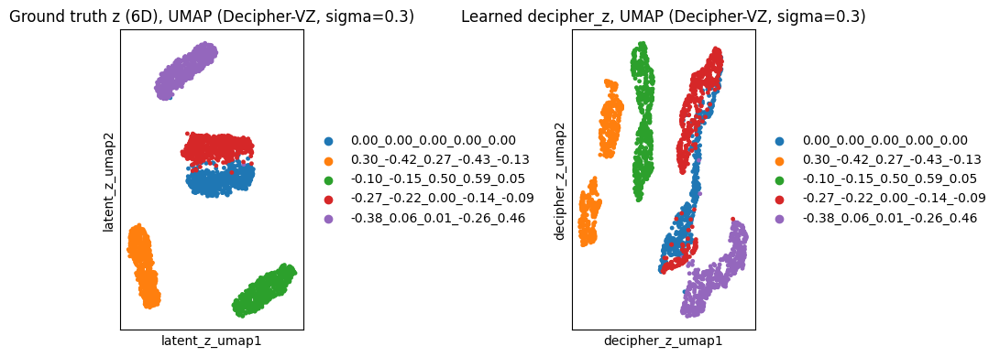

Decipher-VZ2  sigma=0.3  ground truth z silhouette (by batch) = 0.3394
Decipher-VZ2  sigma=0.3  learned decipher_z silhouette (by batch) = 0.2878


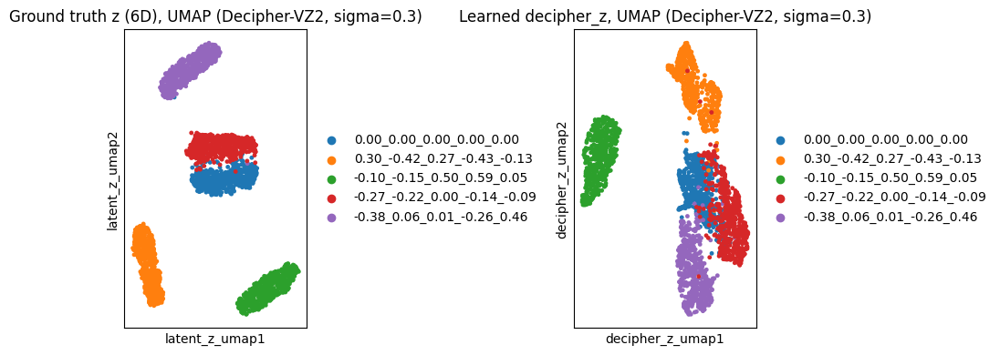

Decipher-MF  sigma=0.3  ground truth z silhouette (by batch) = 0.3394
Decipher-MF  sigma=0.3  learned decipher_z silhouette (by batch) = -0.0235


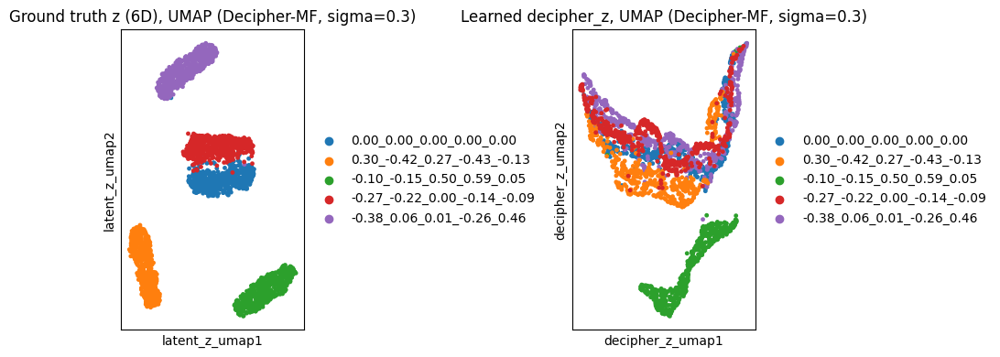

In [19]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.4

In [20]:
sigma = 0.4
runs = {name: load_run(results_df_high, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

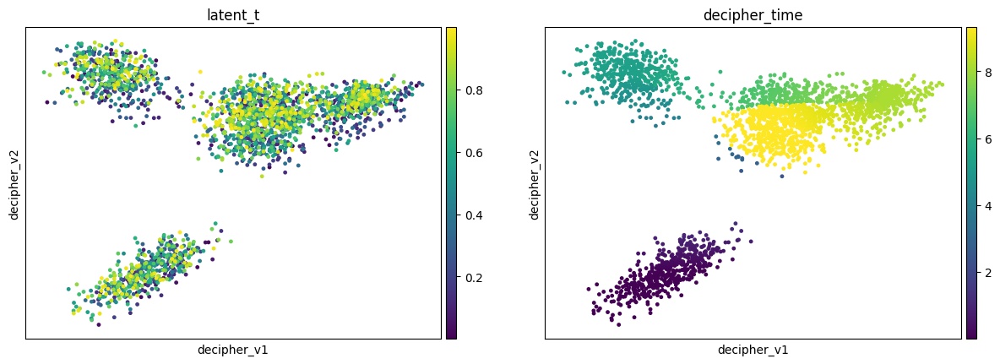

Base Decipher, sigma=0.4, seed=0, rho = 0.0330


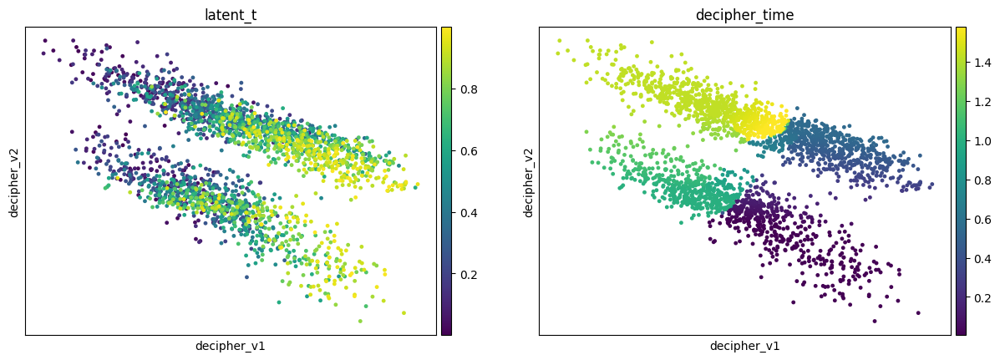

Decipher-VZ, sigma=0.4, seed=0, rho = 0.4528


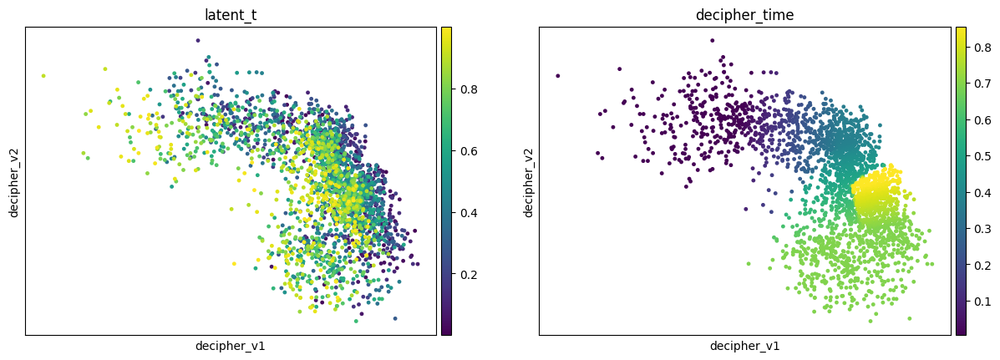

Decipher-VZ2, sigma=0.4, seed=0, rho = 0.0896


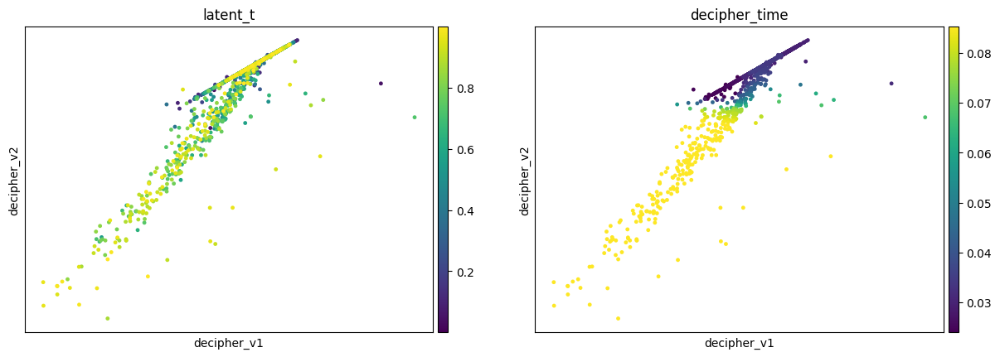

Decipher-MF, sigma=0.4, seed=0, rho = 0.2404


In [21]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.4  ground truth z silhouette (by batch) = 0.4469
Base Decipher  sigma=0.4  learned decipher_z silhouette (by batch) = 0.5188


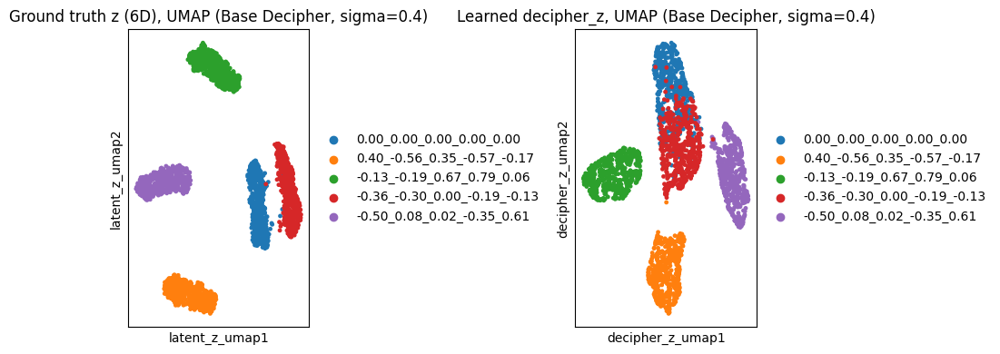

Decipher-VZ  sigma=0.4  ground truth z silhouette (by batch) = 0.4469
Decipher-VZ  sigma=0.4  learned decipher_z silhouette (by batch) = 0.7263


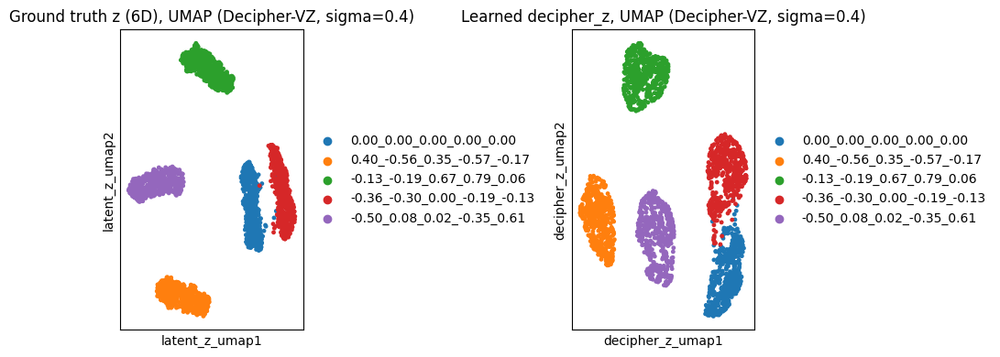

Decipher-VZ2  sigma=0.4  ground truth z silhouette (by batch) = 0.4469
Decipher-VZ2  sigma=0.4  learned decipher_z silhouette (by batch) = 0.3767


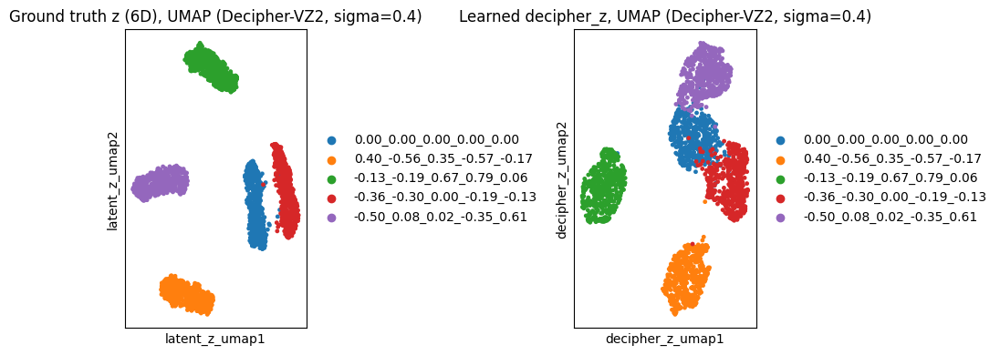

Decipher-MF  sigma=0.4  ground truth z silhouette (by batch) = 0.4469
Decipher-MF  sigma=0.4  learned decipher_z silhouette (by batch) = 0.2112


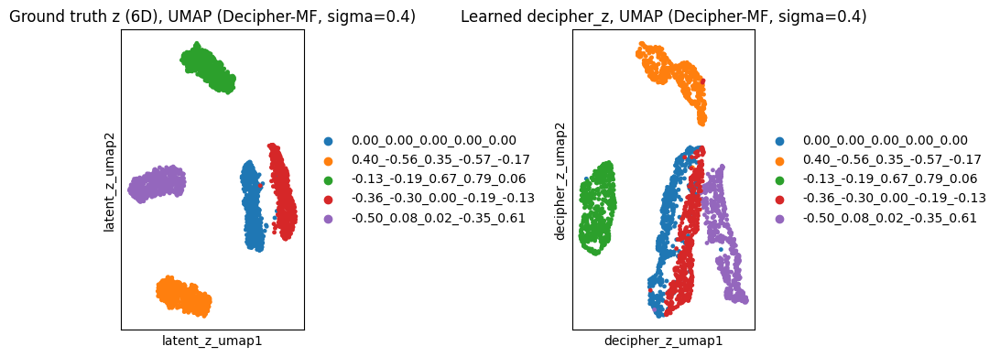

In [22]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()

### Sigma = 0.5

In [23]:
sigma = 0.5
runs = {name: load_run(results_df_high, sigma, name, seed=seed_for_detail) for name in model_names}

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### Latent vs. learned pseudotime

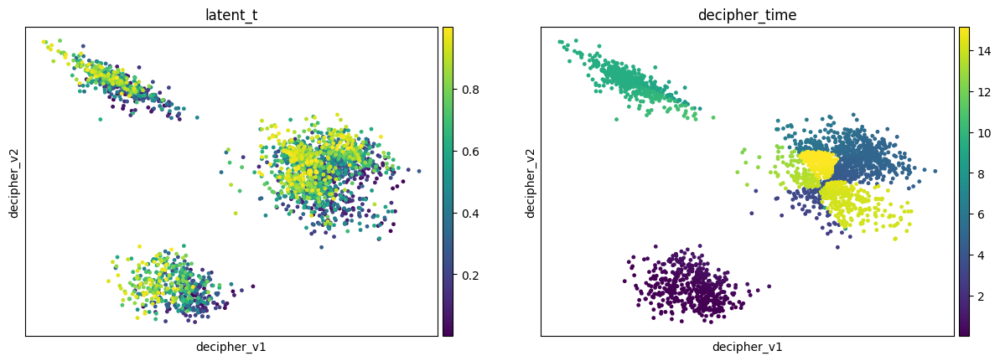

Base Decipher, sigma=0.5, seed=0, rho = 0.0959


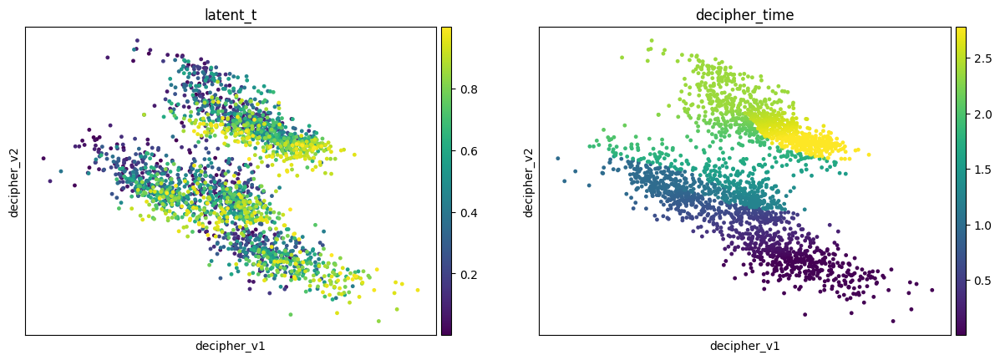

Decipher-VZ, sigma=0.5, seed=0, rho = 0.0386


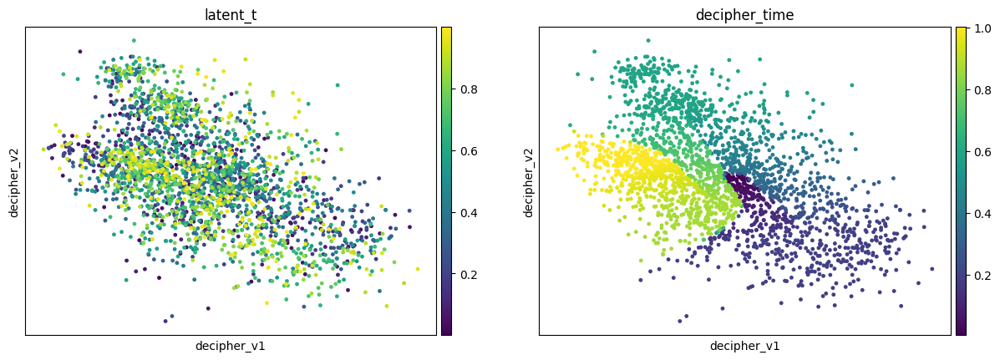

Decipher-VZ2, sigma=0.5, seed=0, rho = 0.0388


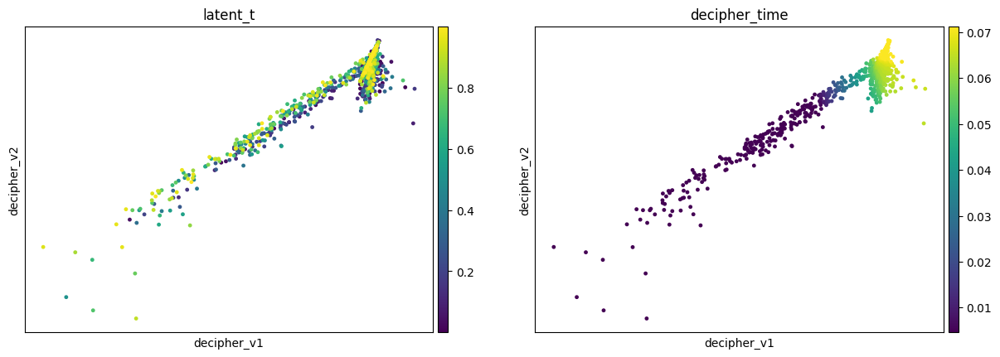

Decipher-MF, sigma=0.5, seed=0, rho = 0.0012


In [24]:
for model_name, (row, adata) in runs.items():
    sc.pl.embedding(adata, basis="decipher_v", color=["latent_t", "decipher_time"])
    print(f"{model_name}, sigma={sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Ground truth vs. inferred z

Base Decipher  sigma=0.5  ground truth z silhouette (by batch) = 0.5256
Base Decipher  sigma=0.5  learned decipher_z silhouette (by batch) = 0.5878


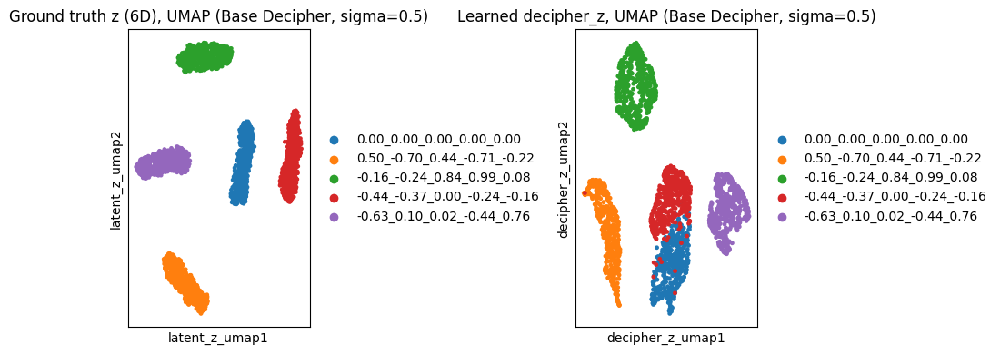

Decipher-VZ  sigma=0.5  ground truth z silhouette (by batch) = 0.5256
Decipher-VZ  sigma=0.5  learned decipher_z silhouette (by batch) = 0.7780


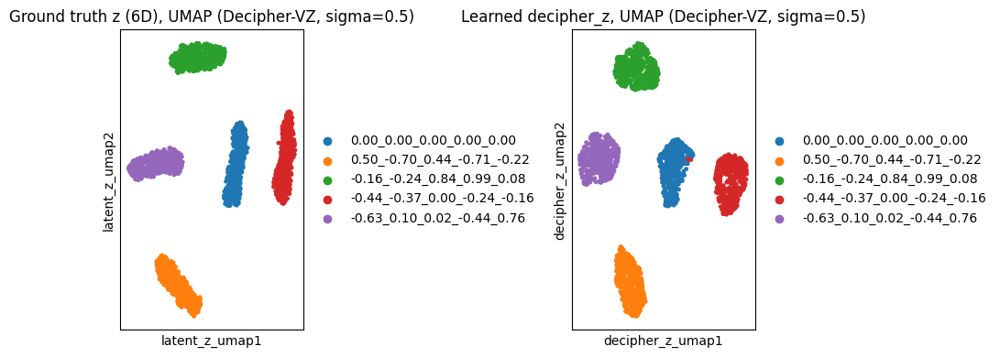

Decipher-VZ2  sigma=0.5  ground truth z silhouette (by batch) = 0.5256
Decipher-VZ2  sigma=0.5  learned decipher_z silhouette (by batch) = 0.5456


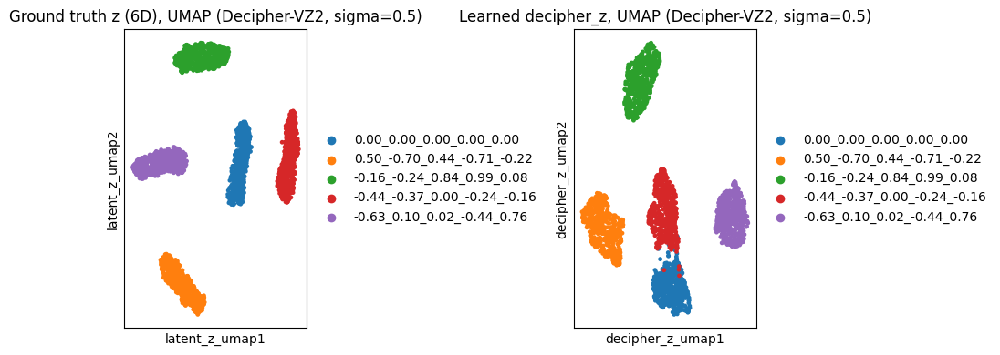

Decipher-MF  sigma=0.5  ground truth z silhouette (by batch) = 0.5256
Decipher-MF  sigma=0.5  learned decipher_z silhouette (by batch) = 0.5661


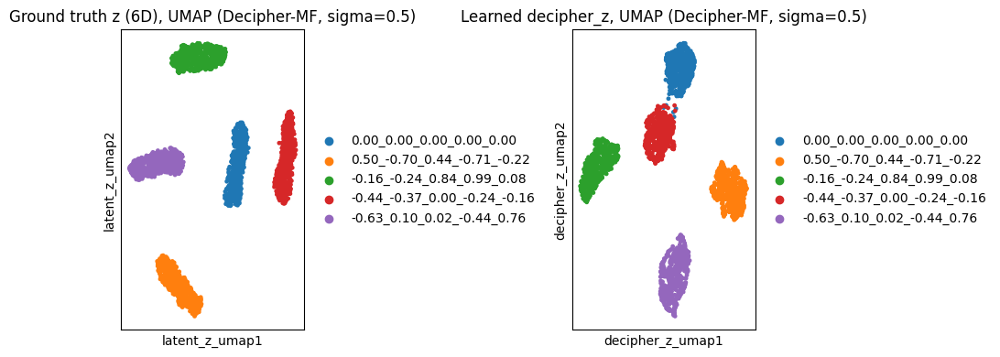

In [25]:
for model_name, (row, adata) in runs.items():
    batch_labels = adata.obs["batch"].astype(str)

    sil_ground_truth = silhouette_score(
        adata.obs[latent_z_cols].values, batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    sil_learned = silhouette_score(
        adata.obsm["decipher_z"], batch_labels,
        sample_size=min(5000, adata.n_obs), random_state=42,
    )
    print(f"{model_name}  sigma={sigma}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
    print(f"{model_name}  sigma={sigma}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

    adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
    sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
    sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
    adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

    sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
    sc.tl.umap(adata, random_state=42)
    adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
    sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                    ax=axes[0], show=False, title=f"Ground truth z (6D), UMAP ({model_name}, sigma={sigma})")
    sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                    ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={sigma})")
    plt.tight_layout()
    plt.show()